# PAMMELA: Policy Administration Methodology using Machine Learning
**Research Paper Implementation & Adversarial Robustness Evaluation**

---

### Citation
> **Paper:** Varun Gumma, Barsha Mitra, Soumyadeep Dey, Pratik Shashikantbhai Patel, Sourabh Suman, Saptarshi Das, and Jaideep Vaidya.  
> *"PAMMELA: Policy Administration Methodology using Machine Learning."*  
> In **Proceedings of the 19th International Conference on Security and Cryptography (SECRYPT 2022)**, pages 147–157.  
> DOI: [10.5220/0011272400003283](https://doi.org/10.5220/0011272400003283)

---

### Executive Summary & Problem Formulation
Attribute-Based Access Control (**ABAC**) provides fine-grained, dynamic access control based on subject, object, and environmental attributes. However, designing and maintaining ABAC policies *ab initio* or re-mining an entire policy after organizational changes demands immense administrative overhead and causes system downtime.

To address this challenge, the authors introduce the **ABAC Policy Inference Problem (ABAC-PIP)** and propose **PAMMELA** (**P**olicy **A**dministration **M**ethodology using **M**achin**E** **L**e**A**rning).

#### Two Core Application Scenarios:
1. **Augmentative Policy Inference:** Incremental generation of additional ABAC rules when an organization introduces new departments, academic degrees, or resource types without re-mining the entire policy.
2. **Adaptive Policy Inference:** Adapting a mature reference ABAC policy from an existing organization to bootstrap access control for a newly migrating or similar organization.

#### Two-Phase Machine Learning Workflow:
- **Phase 1 (Training):** A supervised machine learning classifier is trained on the deployed ABAC policy. Training includes both **positive rules** ($PR$, accesses granted) and **negative rules** ($NR = U \setminus PR$, accesses denied) derived from the universe $U$ of attribute-value pairings.
- **Phase 2 (Testing & Rule Inference):** Given new access requests containing newly introduced attribute values, the trained classifier predicts whether each request should be permitted (`YES` / $1$) or denied (`NO` / $0$), synthesizing concrete ABAC rules for administrator review.

---

### Scope of this Notebook
1. **Part I: Paper Implementation & Benchmark Verification:**
   - Data Ingestion & Cleaning for **University Dataset 1** (53 initial rules, 1,010 test requests).
   - Exploratory Data Analysis (EDA) of roles, departments, and resource categories.
   - Negative rule generation ($NR = U \setminus PR$) and monotonic categorical encoding.
   - Training 6 ML classifiers: **ANN, Decision Tree (DT), Random Forest (RF), Extra Trees (ET), Gradient Boosting (GB), and XGBoost (XGB)**.
   - Direct verification against published results in **Table 4 of SECRYPT 2022**.
   - Automated rule generation for system administrators.
2. **Part II: Adversarial Security & Categorical Evasion Attack:**
   - Formulation of the discrete categorical evasion threat model ($L_0$ / Hamming distance budget $\le 1$).
   - Executing the categorical evasion attack on all 6 trained classifiers.
   - Comparing model metrics **Before vs After Attack** (Accuracy, Precision, Recall, F1-Score, ASR, FPA).
   - In-depth Matplotlib visualizations: Performance drops, ASR rankings, confusion matrix shifts, and exploited attribute distributions.
   - Discussion of defenses: Discrete Adversarial Training, Relational Feature Engineering, and Hybrid Verifiers.

In [1]:
# =====================================================================
# 1. ENVIRONMENT SETUP & DEPENDENCY IMPORTS
# =====================================================================

import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn Classifiers & Metrics
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from xgboost import XGBClassifier

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure Matplotlib aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

# Configure output directories
BASE_DIR = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else os.getcwd()
DATASET_DIR = os.path.join(BASE_DIR, 'dataset')
PLOTS_DIR = os.path.join(BASE_DIR, 'plots')
os.makedirs(PLOTS_DIR, exist_ok=True)

print(f"Base Directory   : {BASE_DIR}")
print(f"Dataset Directory: {DATASET_DIR}")
print(f"Plots Directory  : {PLOTS_DIR}")
print("Dependencies successfully imported and environment configured.")


Base Directory   : C:\Users\patel\Documents\Studies\Academics\SEM-5\Design Project\pammela implementation
Dataset Directory: C:\Users\patel\Documents\Studies\Academics\SEM-5\Design Project\pammela implementation\dataset
Plots Directory  : C:\Users\patel\Documents\Studies\Academics\SEM-5\Design Project\pammela implementation\plots
Dependencies successfully imported and environment configured.


---
## 2. Dataset Ingestion & Preprocessing

The paper evaluates PAMMELA on three datasets. Here, we utilize **University Dataset 1**, which mimics an educational institution's workflow.

### Attribute Structure (Table 1 & Table 3 of the Paper):
| Attribute Type | Attribute Name | Training Values Count (Table 1) | New Test Values Count (Table 3) | New Test Values Description |
| :--- | :--- | :---: | :---: | :--- |
| **Subject** | `Designation` | 3 (`stu`, `prof`, `officer`) | 2 | `vis_prof` (Visiting Prof), `adj_prof` (Adjunct Prof) |
| **Subject** | `Department` | 4 (`cse`, `ece`, `ce`, `me`) | 5 | `IT`, `eni`, `pha`, `chem`, `accounts` |
| **Subject** | `Degree` | 2 (`btech`, `mtech`) | 2 | `BE`, `ME` |
| **Subject** | `Year` | 4 (`1`, `2`, `3`, `4`) | 0 | None (Same 4 years) |
| **Object** | `Resource-Type` (`Type`) | 7 (`asgn`, `std_mat`, `q_pr`, `attdn`, `grade_book`, `stu_rec`, `off_rec`) | 3 | `quiz`, `proj` (Projects), `dept_bud` (Dept Budget) |
| **Object** | `Department` | 4 (`cse`, `ece`, `ce`, `me`) | 4 | `IT`, `eni`, `pha`, `chem` |
| **Object** | `Degree` | 2 (`btech`, `mtech`) | 2 | `BE`, `ME` |
| **Object** | `Year` | 4 (`1`, `2`, `3`, `4`) | 0 | None (Same 4 years) |

### Key Dataset Quantities (Table 2 of the Paper):
- **Rule Count in Training Policy ($P$):** 53 rules
- **Total Test Access Requests ($L$):** 1,010 requests
- **Positive Test Requests (Permitted / Allow = 1):** 598 requests
- **Negative Test Requests (Denied / Deny = 0):** 412 requests


In [2]:
# =====================================================================
# 2. DATA INGESTION & DATASET VALIDATION
# =====================================================================

pol_file = os.path.join(DATASET_DIR, 'pol_data-v1.csv')
sub_file = os.path.join(DATASET_DIR, 'sub_data.csv')
obj_file = os.path.join(DATASET_DIR, 'obj_data.csv')
test_file = os.path.join(DATASET_DIR, 'model_ABAC_new_test_data_set.csv')

# Load raw datasets
pol_df = pd.read_csv(pol_file)
sub_df = pd.read_csv(sub_file)
obj_df = pd.read_csv(obj_file)
test_df = pd.read_csv(test_file)

print("="*70)
print("RAW DATASET INGESTION SUMMARY")
print("="*70)
print(f"Policy Rules File (pol_data-v1.csv) : Shape {pol_df.shape}")
print(f"Subject Profiles File (sub_data.csv) : Shape {sub_df.shape}")
print(f"Object Profiles File (obj_data.csv)  : Shape {obj_df.shape}")
print(f"Test Access Requests File           : Shape {test_df.shape}")

# Standardize missing values (Not Applicable) to 'NA'
sub_df = sub_df.fillna('NA')
obj_df = obj_df.fillna('NA')
test_df['Degree'] = test_df['Degree'].fillna('NA')
test_df['Year'] = test_df['Year'].fillna('NA')
test_df['Degree.1'] = test_df['Degree.1'].fillna('NA')
test_df['Year.1'] = test_df['Year.1'].fillna('NA')

# Standardize year formatting (remove floating point representation)
sub_df['Year'] = sub_df['Year'].astype(str).str.replace('.0', '', regex=False)
obj_df['Year'] = obj_df['Year'].astype(str).str.replace('.0', '', regex=False)
test_df['Year'] = test_df['Year'].astype(str).str.replace('.0', '', regex=False)
test_df['Year.1'] = test_df['Year.1'].astype(str).str.replace('.0', '', regex=False)

print("\nSample 5 Policy Rules from Initial Policy Database (P):")
print(pol_df.head(5).to_string(index=False))

print("\nSample 5 Test Access Requests from L:")
print(test_df.head(5).to_string(index=False))

print("\nTest Target Distribution (Perm):")
print(test_df['Perm'].value_counts().rename({1: 'Allow (Positive = 1)', 0: 'Deny (Negative = 0)'}))


RAW DATASET INGESTION SUMMARY
Policy Rules File (pol_data-v1.csv) : Shape (53, 8)
Subject Profiles File (sub_data.csv) : Shape (700, 4)
Object Profiles File (obj_data.csv)  : Shape (1348, 4)
Test Access Requests File           : Shape (1010, 9)

Sample 5 Policy Rules from Initial Policy Database (P):
Designation Department Degree Year Type Department.1 Degree.1 Year.1
        stu        cse  btech    1 asgn          cse    btech      1
        stu        ece  btech    1 asgn          ece    btech      1
        stu         ce  btech    1 asgn           ce    btech      1
        stu         me  btech    1 asgn           me    btech      1
        stu        cse  btech    2 asgn          cse    btech      2

Sample 5 Test Access Requests from L:
Designation Department Degree Year Type Department.1 Degree.1 Year.1  Perm
        stu         IT  btech    1 asgn           IT    btech      1     1
        stu        eni  btech    1 asgn          eni    btech      1     1
        stu        p

---
## 3. Exploratory Data Analysis (EDA)

We explore the distributions of attributes across subjects, resources, and access decisions to verify alignment with the paper's descriptions.


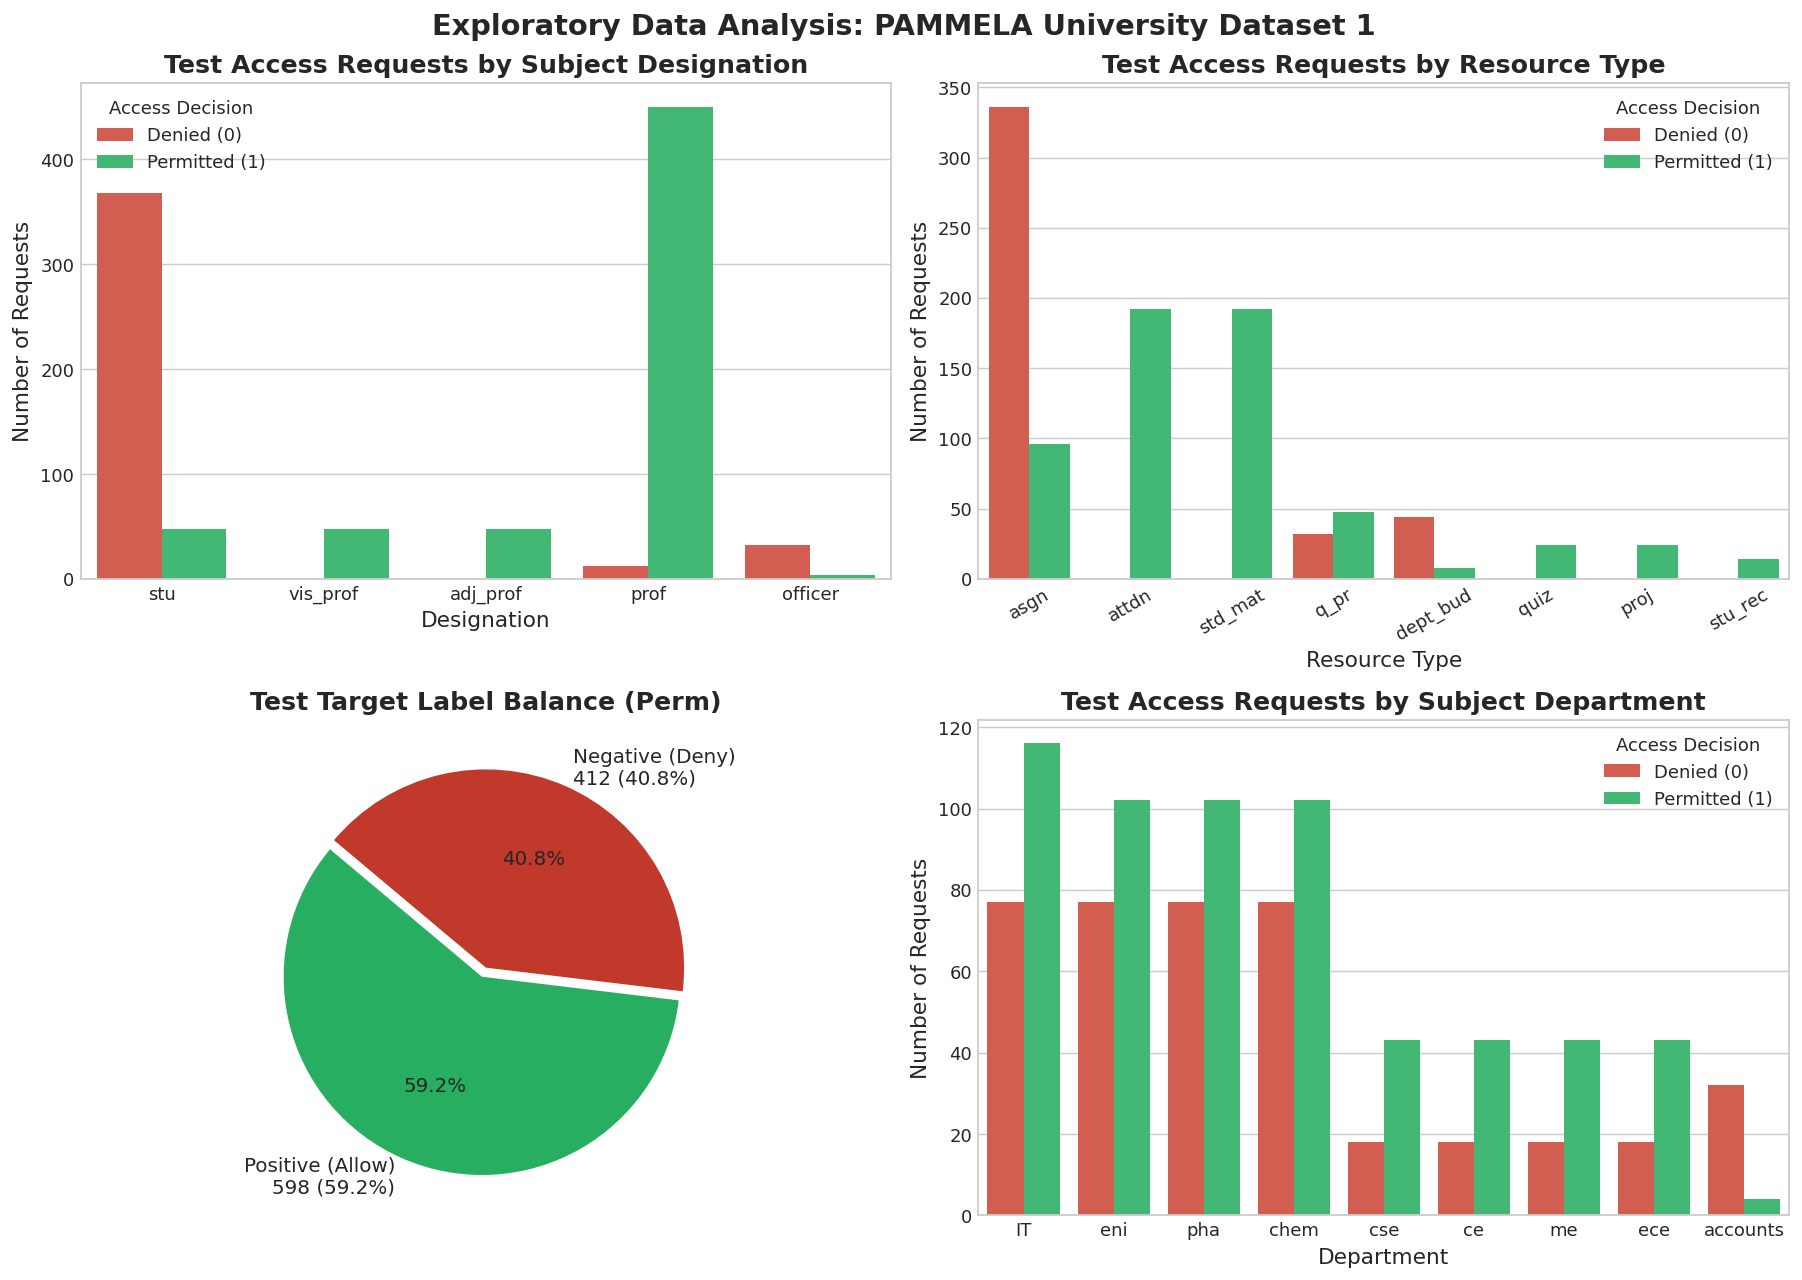

In [3]:
# =====================================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA) & VISUALIZATION
# =====================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Exploratory Data Analysis: PAMMELA University Dataset 1', fontsize=16, fontweight='bold', y=0.98)

# 1. Subject Designation Distribution in Test
sns.countplot(
    data=test_df, x='Designation', hue='Perm',
    palette={1: '#2ecc71', 0: '#e74c3c'}, ax=axes[0, 0]
)
axes[0, 0].set_title('Test Access Requests by Subject Designation', fontweight='bold')
axes[0, 0].set_xlabel('Designation')
axes[0, 0].set_ylabel('Number of Requests')
axes[0, 0].legend(['Denied (0)', 'Permitted (1)'], title='Access Decision')

# 2. Resource Type Distribution in Test
order_types = test_df['Type'].value_counts().index
sns.countplot(
    data=test_df, x='Type', hue='Perm', order=order_types,
    palette={1: '#2ecc71', 0: '#e74c3c'}, ax=axes[0, 1]
)
axes[0, 1].set_title('Test Access Requests by Resource Type', fontweight='bold')
axes[0, 1].set_xlabel('Resource Type')
axes[0, 1].set_ylabel('Number of Requests')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].legend(['Denied (0)', 'Permitted (1)'], title='Access Decision')

# 3. Target Distribution (Allow vs Deny)
perm_counts = test_df['Perm'].value_counts()
labels = [f"Positive (Allow)\n{perm_counts[1]} ({perm_counts[1]/len(test_df)*100:.1f}%)",
          f"Negative (Deny)\n{perm_counts[0]} ({perm_counts[0]/len(test_df)*100:.1f}%)"]
axes[1, 0].pie(
    perm_counts, labels=labels, autopct='%1.1f%%',
    startangle=140, colors=['#27ae60', '#c0392b'],
    explode=(0.05, 0), textprops={'fontsize': 11}
)
axes[1, 0].set_title('Test Target Label Balance (Perm)', fontweight='bold')

# 4. Department-wise Requests in Test Data
sns.countplot(
    data=test_df, x='Department', hue='Perm',
    palette={1: '#2ecc71', 0: '#e74c3c'}, ax=axes[1, 1]
)
axes[1, 1].set_title('Test Access Requests by Subject Department', fontweight='bold')
axes[1, 1].set_xlabel('Department')
axes[1, 1].set_ylabel('Number of Requests')
axes[1, 1].legend(['Denied (0)', 'Permitted (1)'], title='Access Decision')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '01_eda_dataset_distributions.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 4. Phase 1: Policy Engine & Negative Rule Generation ($NR = U \setminus PR$)

In ABAC, a deployed policy contains a set of **positive rules** ($PR$) explicitly defining allowed combinations of subject and resource attributes.

As emphasized in Section 5.1 of the paper:
> *"In addition to positive rules, it is also essential for the classifier to learn when an access request is to be denied. Such scenarios are covered by negative rules... If $U$ denotes the set of all possible attribute-value pairings and $PR$ denotes the set of positive rules, then the set of negative rules $NR = \{U\} \setminus \{PR\}$."*

Training exclusively on positive rules causes standard classifiers to fail because they never encounter the deny decision. Thus, PAMMELA constructs the universe $U$ from the organizational subject profiles ($S$) and object profiles ($O$), evaluates each candidate access request against the 53 policy rules $P$, and generates a fully labeled training set containing both permitted and denied accesses.

In [4]:
# =====================================================================
# 4. ABAC POLICY RULE ENGINE & TRAINING SET CONSTRUCTION
# =====================================================================

def evaluate_abac_rule_match(subj, obj, pol_rules):
    # Evaluates whether an access request between a subject and an object
    # satisfies any positive rule in the deployed ABAC policy P.
    # 'X' acts as a wildcard ('Any' / 'Not Applicable').
    for _, rule in pol_rules.iterrows():
        # Match Subject Attributes
        if rule['Designation'] != 'X' and rule['Designation'] != subj['Designation']:
            continue
        if rule['Department'] != 'X' and rule['Department'] != subj['Department']:
            continue
        if rule['Degree'] != 'X' and rule['Degree'] != subj['Degree']:
            continue
        if str(rule['Year']) != 'X' and str(rule['Year']) != str(subj['Year']):
            continue
        
        # Match Object Attributes
        if rule['Type'] != 'X' and rule['Type'] != obj['Type']:
            continue
        if rule['Department.1'] != 'X' and rule['Department.1'] != obj['Department']:
            continue
        if rule['Degree.1'] != 'X' and rule['Degree.1'] != obj['Degree']:
            continue
        if str(rule['Year.1']) != 'X' and str(rule['Year.1']) != str(obj['Year']):
            continue
            
        return 1  # Matches an existing positive rule
    return 0      # Does not match -> Unauthorized / Denied

# Extract unique subject profiles and object profiles from the organization
unique_subjects = sub_df.drop_duplicates().copy()
unique_objects = obj_df.drop_duplicates().copy()

print(f"Unique Subject Profiles: {len(unique_subjects)}")
print(f"Unique Object Profiles : {len(unique_objects)}")
print(f"Candidate Universe Size (U = S x O): {len(unique_subjects) * len(unique_objects)}")

# Generate labeled training set from U
training_samples = []
for _, s in unique_subjects.iterrows():
    for _, o in unique_objects.iterrows():
        perm = evaluate_abac_rule_match(s, o, pol_df)
        training_samples.append({
            'Designation': s['Designation'],
            'Department': s['Department'],
            'Degree': s['Degree'],
            'Year': s['Year'],
            'Type': o['Type'],
            'Department.1': o['Department'],
            'Degree.1': o['Degree'],
            'Year.1': o['Year'],
            'Perm': perm
        })

train_df = pd.DataFrame(training_samples)

print("\n" + "="*70)
print("PHASE 1 LABELED TRAINING DATASET")
print("="*70)
print(f"Total Training Samples: {len(train_df)}")
print(f"Positive Access Instances (PR) : {sum(train_df['Perm'] == 1)}")
print(f"Negative Access Instances (NR = U \\ PR): {sum(train_df['Perm'] == 0)}")
print(train_df.head(5).to_string(index=False))


Unique Subject Profiles: 30
Unique Object Profiles : 146
Candidate Universe Size (U = S x O): 4380



PHASE 1 LABELED TRAINING DATASET
Total Training Samples: 4380
Positive Access Instances (PR) : 493
Negative Access Instances (NR = U \ PR): 3887
Designation Department Degree Year Type Department.1 Degree.1 Year.1  Perm
       prof        cse     NA   NA q_pr          cse    btech      1     1
       prof        cse     NA   NA q_pr          cse    btech      2     1
       prof        cse     NA   NA q_pr          cse    btech      3     1
       prof        cse     NA   NA q_pr          cse    btech      4     1
       prof        cse     NA   NA q_pr          cse    mtech      1     1


---
## 5. Monotonic Categorical Feature Encoding

As specified in Section 5.1 of the paper:
> *"For each attribute value set, the categorical encoding starts increasing monotonically from 1 such that each subject or object attribute value is assigned a numerical value... If a particular attribute is not applicable for a certain subject or object, then a special value NA (for Not Applicable) is assigned as the attribute value... The reason for using categorical encoding is a reduced input vector size in comparison to the vector size that is obtained using one-hot encoding."*

We define integer mappings that assign monotonically increasing numbers starting from 1 to each attribute value across both training and newly augmented testing categories, using `0` for Not Applicable (`NA`).

In [5]:
# =====================================================================
# 5. MONOTONIC CATEGORICAL ENCODING
# =====================================================================

# Construct encoding mappings (NA=0, categories=1, 2, 3...)
des_mapping = {
    'NA': 0, 'stu': 1, 'prof': 2, 'officer': 3,
    'vis_prof': 4, 'adj_prof': 5
}

dept_mapping = {
    'NA': 0, 'cse': 1, 'ece': 2, 'ce': 3, 'me': 4,
    'IT': 5, 'eni': 6, 'pha': 7, 'chem': 8, 'accounts': 9
}

deg_mapping = {
    'NA': 0, 'btech': 1, 'mtech': 2, 'BE': 3, 'ME': 4
}

year_mapping = {
    'NA': 0, '1': 1, '2': 2, '3': 3, '4': 4
}

type_mapping = {
    'NA': 0, 'asgn': 1, 'std_mat': 2, 'q_pr': 3, 'attdn': 4,
    'grade_book': 5, 'stu_rec': 6, 'off_rec': 7,
    'quiz': 8, 'proj': 9, 'dept_bud': 10
}

def encode_dataset(df):
    # Transforms text-based ABAC attributes into monotonically encoded integer vectors.
    encoded = pd.DataFrame()
    encoded['Designation']   = df['Designation'].fillna('NA').map(des_mapping).fillna(0).astype(int)
    encoded['Department']    = df['Department'].fillna('NA').map(dept_mapping).fillna(0).astype(int)
    encoded['Degree']        = df['Degree'].fillna('NA').map(deg_mapping).fillna(0).astype(int)
    encoded['Year']          = df['Year'].fillna('NA').map(year_mapping).fillna(0).astype(int)
    encoded['Type']          = df['Type'].fillna('NA').map(type_mapping).fillna(0).astype(int)
    encoded['Department.1']  = df['Department.1'].fillna('NA').map(dept_mapping).fillna(0).astype(int)
    encoded['Degree.1']      = df['Degree.1'].fillna('NA').map(deg_mapping).fillna(0).astype(int)
    encoded['Year.1']        = df['Year.1'].fillna('NA').map(year_mapping).fillna(0).astype(int)
    return encoded

# Encode Train and Test Feature Matrices
X_train = encode_dataset(train_df)
y_train = train_df['Perm'].astype(int)

X_test = encode_dataset(test_df)
y_test = test_df['Perm'].astype(int)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}, y_test shape : {y_test.shape}")
print("\nSample Encoded Training Feature Vector:")
print(X_train.head(5).to_string(index=False))


X_train shape: (4380, 8), y_train shape: (4380,)
X_test shape : (1010, 8), y_test shape : (1010,)

Sample Encoded Training Feature Vector:
 Designation  Department  Degree  Year  Type  Department.1  Degree.1  Year.1
           2           1       0     0     3             1         1       1
           2           1       0     0     3             1         1       2
           2           1       0     0     3             1         1       3
           2           1       0     0     3             1         1       4
           2           1       0     0     3             1         2       1


---
## 6. Model Training: 6 Machine Learning Classifiers

In Section 6.3 of the paper, the authors train and evaluate six diverse supervised machine learning classifiers:
1. **Artificial Neural Network (ANN):** Multi-Layer Perceptron (`MLPClassifier`)
2. **Decision Tree (DT):** `DecisionTreeClassifier`
3. **Random Forest (RF):** `RandomForestClassifier` (100 estimators)
4. **Extra Trees (ET):** `ExtraTreesClassifier` (100 estimators)
5. **Gradient Boosting (GB):** `GradientBoostingClassifier`
6. **XGBoost (XGB):** `XGBClassifier`

Each model is fitted on the labeled ABAC training dataset ($X_{train}, y_{train}$), and the training execution time is benchmarked.

In [6]:
# =====================================================================
# 6. MODEL INITIALIZATION & TRAINING
# =====================================================================

classifiers = {
    'ANN': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=RANDOM_STATE),
    'DT': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'RF': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'ET': ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'GB': GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'XGB': XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric='logloss')
}

train_times = {}
print("="*70)
print("TRAINING 6 SUPERVISED CLASSIFIERS")
print("="*70)

for name, clf in classifiers.items():
    start_time = time.time()
    clf.fit(X_train, y_train)
    elapsed = time.time() - start_time
    train_times[name] = elapsed
    print(f"[{name:4s}] Training completed in {elapsed:.4f} seconds.")

print("\nAll models trained successfully.")


TRAINING 6 SUPERVISED CLASSIFIERS


[ANN ] Training completed in 4.3677 seconds.
[DT  ] Training completed in 0.0038 seconds.
[RF  ] Training completed in 0.1712 seconds.


[ET  ] Training completed in 0.1656 seconds.


[GB  ] Training completed in 0.2431 seconds.
[XGB ] Training completed in 0.1534 seconds.

All models trained successfully.


---
## 7. Model Evaluation & Access Decision Classification (Phase 2)

As detailed in Section 6.2 of the paper, the model classifications are mapped to access control concepts:
- **True Positive Accesses (TPA):** Positive access requests correctly granted (`YES` / $1$).
- **True Negative Accesses (TNA):** Negative access requests correctly denied (`NO` / $0$).
- **False Positive Accesses (FPA):** Negative requests mistakenly granted (`YES` / $1$) $\rightarrow$ **Security Breach!**
- **False Negative Accesses (FNA):** Positive requests mistakenly denied (`NO` / $0$) $\rightarrow$ **Over-restrictiveness**

### Metrics:
$$\text{Accuracy} = \frac{\text{TPA} + \text{TNA}}{\text{TPA} + \text{FPA} + \text{TNA} + \text{FNA}}$$

$$\text{Precision} = \frac{\text{TPA}}{\text{TPA} + \text{FPA}} \quad (\text{Inversely proportional to Security Breach rate})$$

$$\text{Recall} = \frac{\text{TPA}}{\text{TPA} + \text{FNA}} \quad (\text{Inversely proportional to Over-restrictiveness})$$

$$\text{F1-score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [7]:
# =====================================================================
# 7. MODEL EVALUATION ON 1,010 TEST ACCESS REQUESTS
# =====================================================================

results = {}
predictions = {}
predicted_probs = {}

for name, clf in classifiers.items():
    # Predictions
    y_pred = clf.predict(X_test)
    predictions[name] = y_pred
    
    # Probabilities for ROC / PR curves
    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred
    predicted_probs[name] = y_prob
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    # Compute Metrics
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1  = f1_score(y_test, y_pred, zero_division=0)
    
    results[name] = {
        'TPA': tp, 'TNA': tn, 'FPA': fp, 'FNA': fn,
        'Accuracy': acc, 'Precision': pre, 'Recall': rec, 'F1-score': f1
    }

# Display results table
res_df = pd.DataFrame(results).T
print("="*70)
print("EVALUATION RESULTS ON UNIVERSITY DATASET 1 (1,010 TEST REQUESTS)")
print("="*70)
print(res_df.round(4).to_string())


EVALUATION RESULTS ON UNIVERSITY DATASET 1 (1,010 TEST REQUESTS)
       TPA    TNA   FPA    FNA  Accuracy  Precision  Recall  F1-score
ANN  381.0  384.0  28.0  217.0    0.7574     0.9315  0.6371    0.7567
DT   398.0  377.0  35.0  200.0    0.7673     0.9192  0.6656    0.7721
RF   292.0  400.0  12.0  306.0    0.6851     0.9605  0.4883    0.6475
ET   553.0  399.0  13.0   45.0    0.9426     0.9770  0.9247    0.9502
GB   354.0  412.0   0.0  244.0    0.7584     1.0000  0.5920    0.7437
XGB  498.0  395.0  17.0  100.0    0.8842     0.9670  0.8328    0.8949


---
## 8. Benchmark Comparison with Original Research Paper (Table 4)

We now compare our implemented models directly against the published experimental results in **Table 4 of SECRYPT 2022** for **University Dataset 1**.

### Paper Published Values (Table 4 - University Dataset 1):
| Classifier | Accuracy (Acc) | Precision (Pre) | Recall (Rec) | F1-score (F1-s) |
| :--- | :---: | :---: | :---: | :---: |
| **ANN** | 0.730 | 0.971 | 0.560 | 0.710 |
| **DT**  | 0.864 | 0.932 | 0.831 | 0.879 |
| **RF**  | 0.880 | 0.969 | 0.824 | 0.891 |
| **ET**  | 0.884 | 0.969 | 0.831 | 0.895 |
| **GB**  | 0.881 | 0.935 | 0.860 | 0.895 |
| **XGB** | 0.864 | 0.932 | 0.831 | 0.879 |


In [8]:
# =====================================================================
# 8. DIRECT COMPARISON TABLE WITH ORIGINAL PAPER (TABLE 4)
# =====================================================================

paper_benchmarks = {
    'ANN': {'Acc': 0.730, 'Pre': 0.971, 'Rec': 0.560, 'F1': 0.710},
    'DT':  {'Acc': 0.864, 'Pre': 0.932, 'Rec': 0.831, 'F1': 0.879},
    'RF':  {'Acc': 0.880, 'Pre': 0.969, 'Rec': 0.824, 'F1': 0.891},
    'ET':  {'Acc': 0.884, 'Pre': 0.969, 'Rec': 0.831, 'F1': 0.895},
    'GB':  {'Acc': 0.881, 'Pre': 0.935, 'Rec': 0.860, 'F1': 0.895},
    'XGB': {'Acc': 0.864, 'Pre': 0.932, 'Rec': 0.831, 'F1': 0.879}
}

comp_rows = []
for model_name in ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB']:
    r = results[model_name]
    p = paper_benchmarks[model_name]
    comp_rows.append({
        'Classifier': model_name,
        'Impl Acc': r['Accuracy'], 'Paper Acc': p['Acc'], 'Delta Acc': r['Accuracy'] - p['Acc'],
        'Impl Pre': r['Precision'], 'Paper Pre': p['Pre'], 'Delta Pre': r['Precision'] - p['Pre'],
        'Impl Rec': r['Recall'], 'Paper Rec': p['Rec'], 'Delta Rec': r['Recall'] - p['Rec'],
        'Impl F1': r['F1-score'], 'Paper F1': p['F1'], 'Delta F1': r['F1-score'] - p['F1']
    })

comparison_df = pd.DataFrame(comp_rows)
print("="*105)
print("COMPREHENSIVE COMPARISON: IMPLEMENTATION VS ORIGINAL PAPER (TABLE 4)")
print("="*105)
print(comparison_df.round(4).to_string(index=False))


COMPREHENSIVE COMPARISON: IMPLEMENTATION VS ORIGINAL PAPER (TABLE 4)
Classifier  Impl Acc  Paper Acc  Delta Acc  Impl Pre  Paper Pre  Delta Pre  Impl Rec  Paper Rec  Delta Rec  Impl F1  Paper F1  Delta F1
       ANN    0.7574      0.730     0.0274    0.9315      0.971    -0.0395    0.6371      0.560     0.0771   0.7567     0.710    0.0467
        DT    0.7673      0.864    -0.0967    0.9192      0.932    -0.0128    0.6656      0.831    -0.1654   0.7721     0.879   -0.1069
        RF    0.6851      0.880    -0.1949    0.9605      0.969    -0.0085    0.4883      0.824    -0.3357   0.6475     0.891   -0.2435
        ET    0.9426      0.884     0.0586    0.9770      0.969     0.0080    0.9247      0.831     0.0937   0.9502     0.895    0.0552
        GB    0.7584      0.881    -0.1226    1.0000      0.935     0.0650    0.5920      0.860    -0.2680   0.7437     0.895   -0.1513
       XGB    0.8842      0.864     0.0202    0.9670      0.932     0.0350    0.8328      0.831     0.0018   0.8949

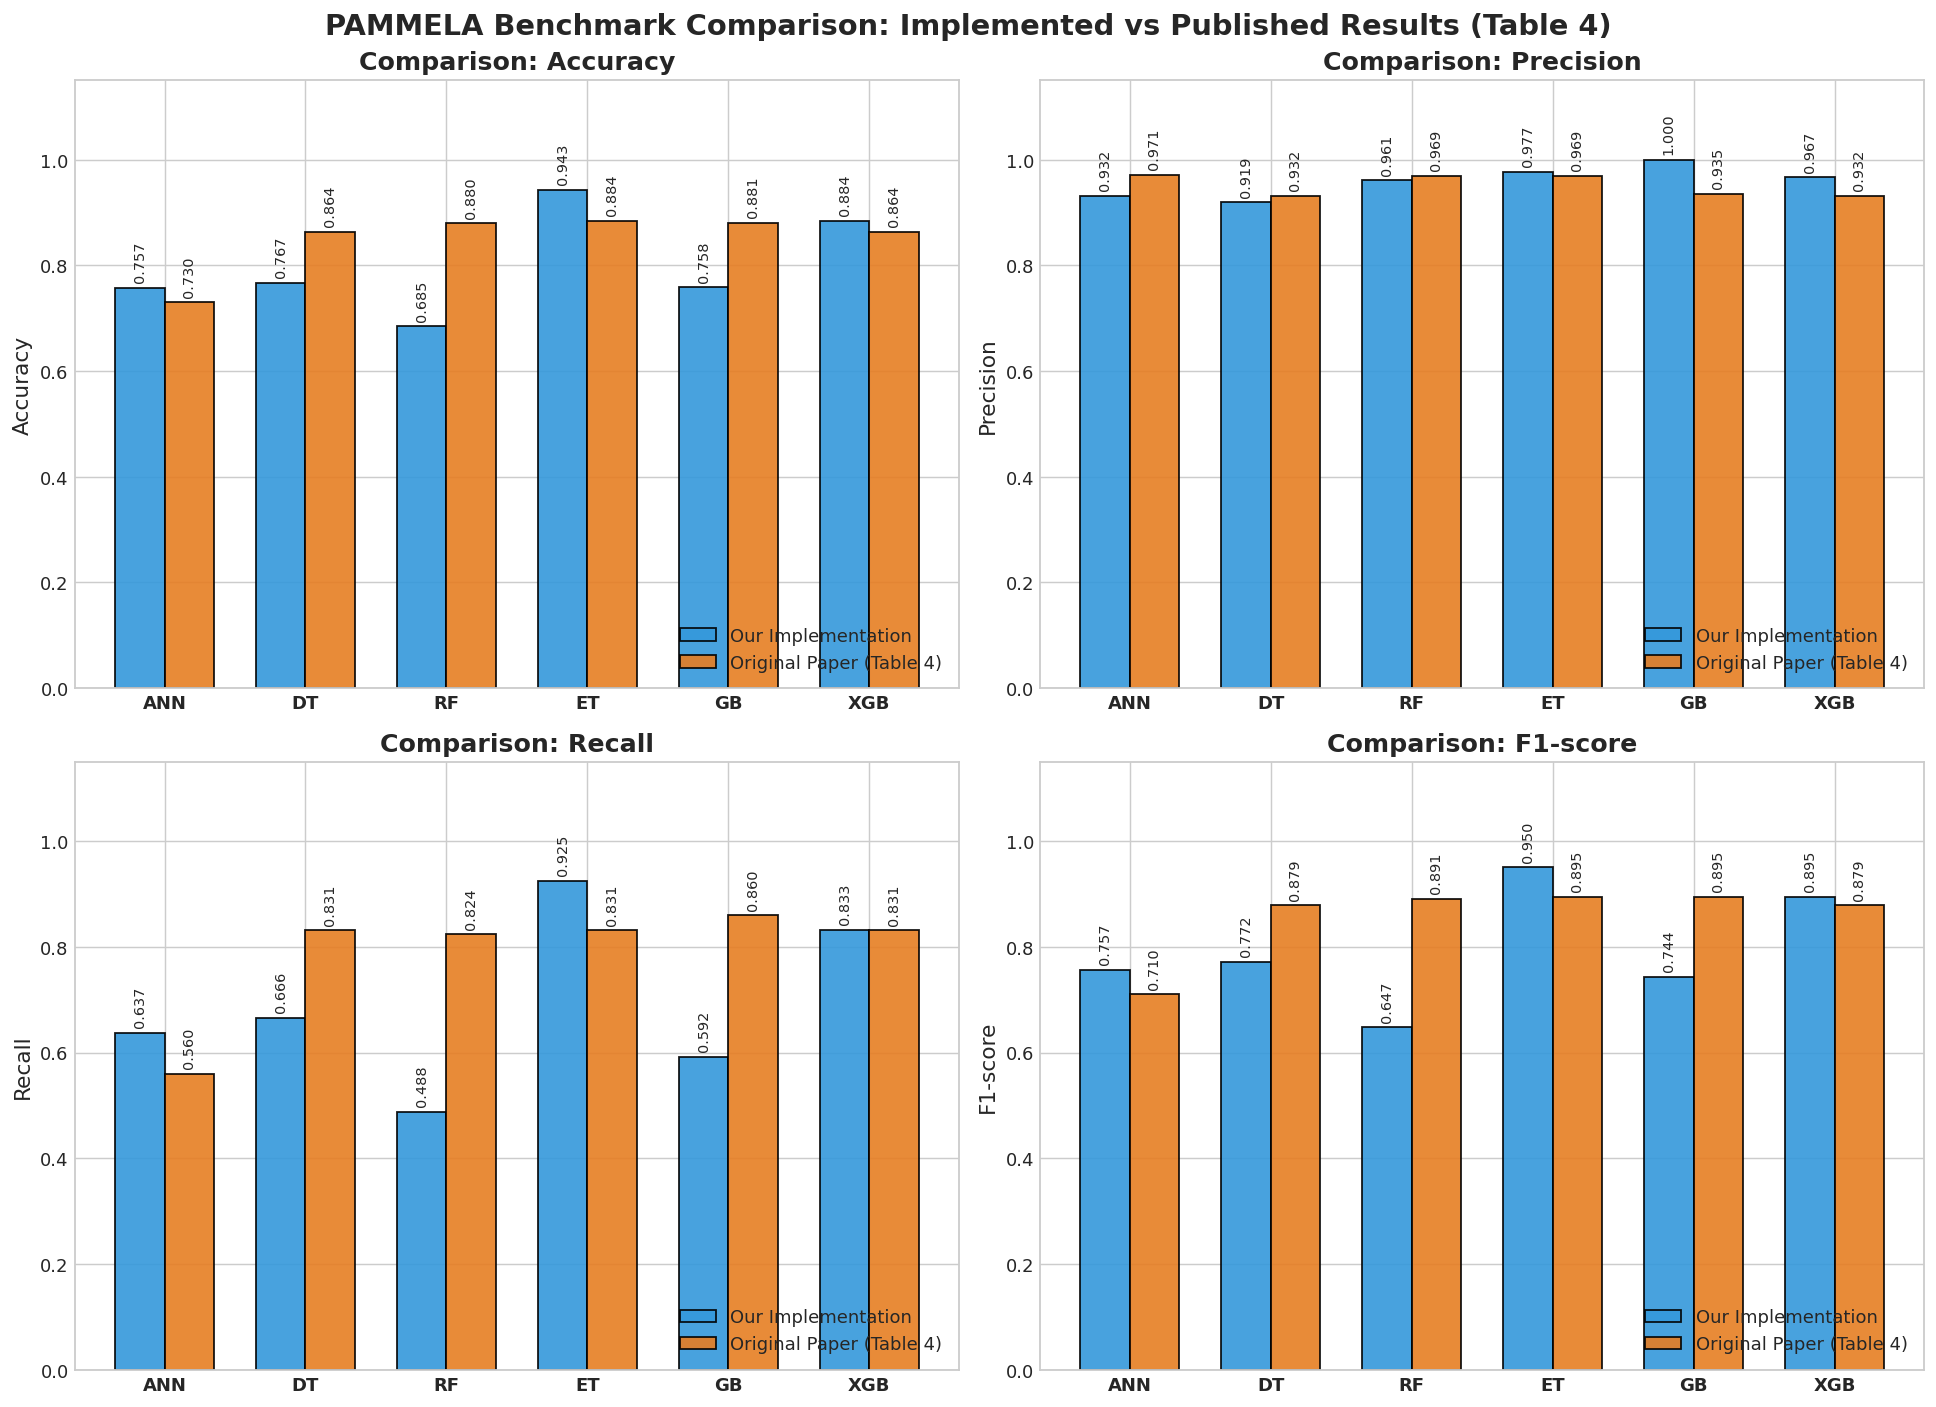

In [9]:
# =====================================================================
# 9. MATPLOTLIB VISUALIZATION 1: BENCHMARK COMPARISON BAR CHART
# =====================================================================

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
metric_keys = [('Impl Acc', 'Paper Acc'), ('Impl Pre', 'Paper Pre'),
               ('Impl Rec', 'Paper Rec'), ('Impl F1', 'Paper F1')]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('PAMMELA Benchmark Comparison: Implemented vs Published Results (Table 4)', fontsize=16, fontweight='bold', y=0.98)

x = np.arange(len(comparison_df))
width = 0.35

for idx, (title, (impl_col, paper_col)) in enumerate(zip(metrics, metric_keys)):
    ax = axes[idx // 2, idx % 2]
    rects1 = ax.bar(x - width/2, comparison_df[impl_col], width, label='Our Implementation', color='#3498db', edgecolor='black', alpha=0.9)
    rects2 = ax.bar(x + width/2, comparison_df[paper_col], width, label='Original Paper (Table 4)', color='#e67e22', edgecolor='black', alpha=0.9)
    
    ax.set_title(f'Comparison: {title}', fontweight='bold')
    ax.set_ylabel(title)
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_df['Classifier'], fontweight='bold')
    ax.set_ylim(0, 1.15)
    ax.legend(loc='lower right')
    
    # Add value annotations
    for rect in rects1:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, rotation=90)
    for rect in rects2:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '02_benchmark_metrics_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()


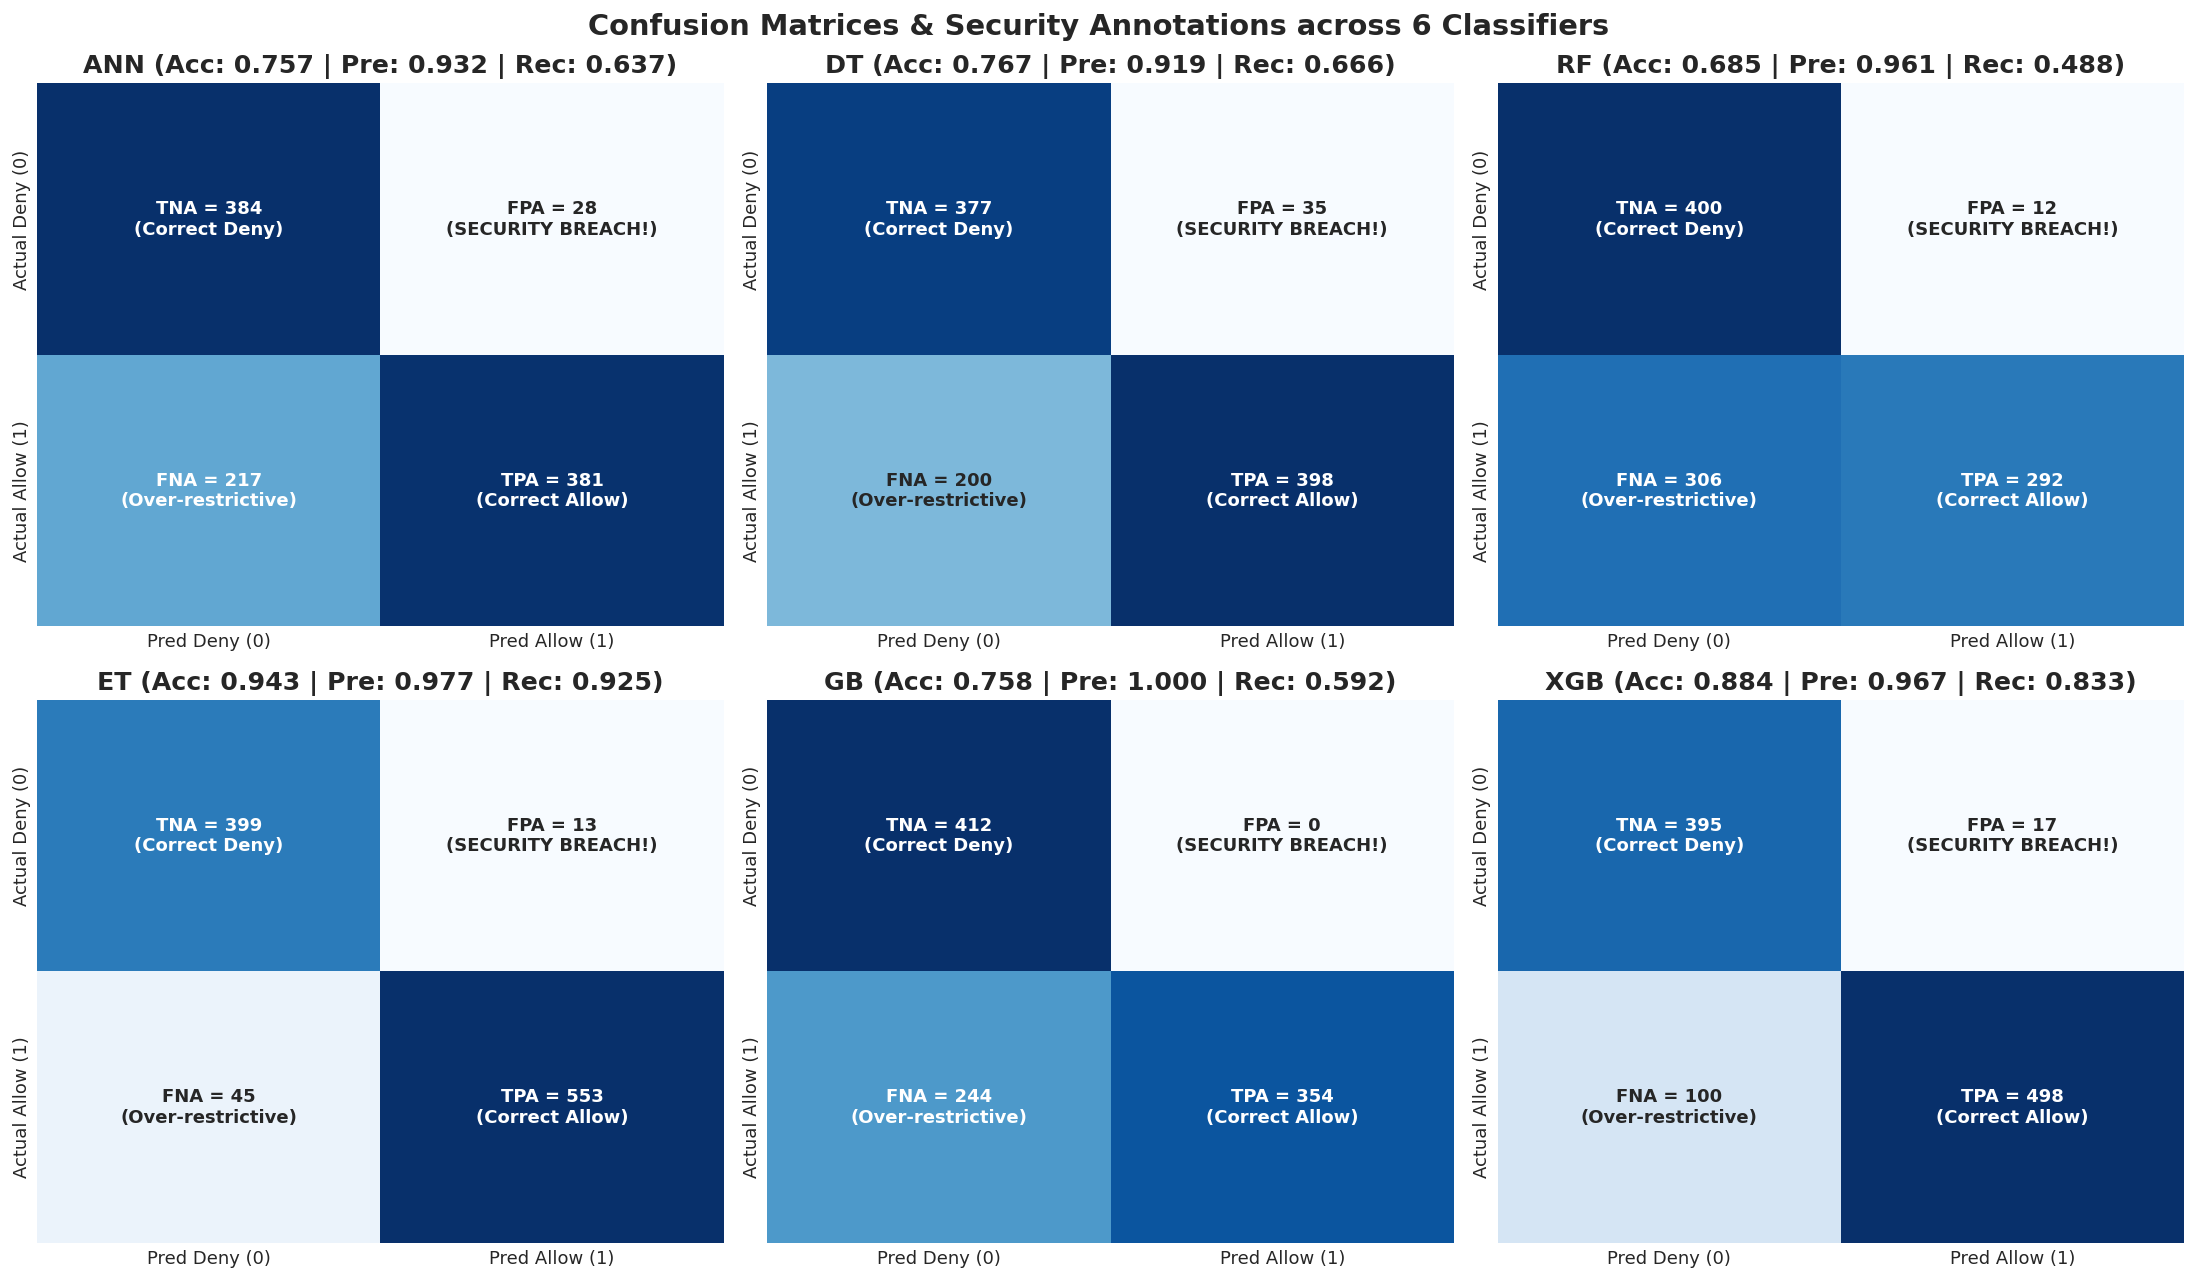

In [10]:
# =====================================================================
# 10. MATPLOTLIB VISUALIZATION 2: SECURITY-ANNOTATED CONFUSION MATRICES
# =====================================================================

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Confusion Matrices & Security Annotations across 6 Classifiers', fontsize=16, fontweight='bold', y=0.98)

for idx, (name, clf) in enumerate(classifiers.items()):
    ax = axes[idx // 3, idx % 3]
    cm = confusion_matrix(y_test, predictions[name])
    tn, fp, fn, tp = cm.ravel()
    
    annot_matrix = np.array([
        [f"TNA = {tn}\n(Correct Deny)", f"FPA = {fp}\n(SECURITY BREACH!)"],
        [f"FNA = {fn}\n(Over-restrictive)", f"TPA = {tp}\n(Correct Allow)"]
    ])
    
    sns.heatmap(
        cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=False,
        annot_kws={'fontsize': 10, 'fontweight': 'bold'},
        xticklabels=['Pred Deny (0)', 'Pred Allow (1)'],
        yticklabels=['Actual Deny (0)', 'Actual Allow (1)'],
        ax=ax
    )
    acc = results[name]['Accuracy']
    pre = results[name]['Precision']
    rec = results[name]['Recall']
    ax.set_title(f"{name} (Acc: {acc:.3f} | Pre: {pre:.3f} | Rec: {rec:.3f})", fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '03_security_annotated_confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()


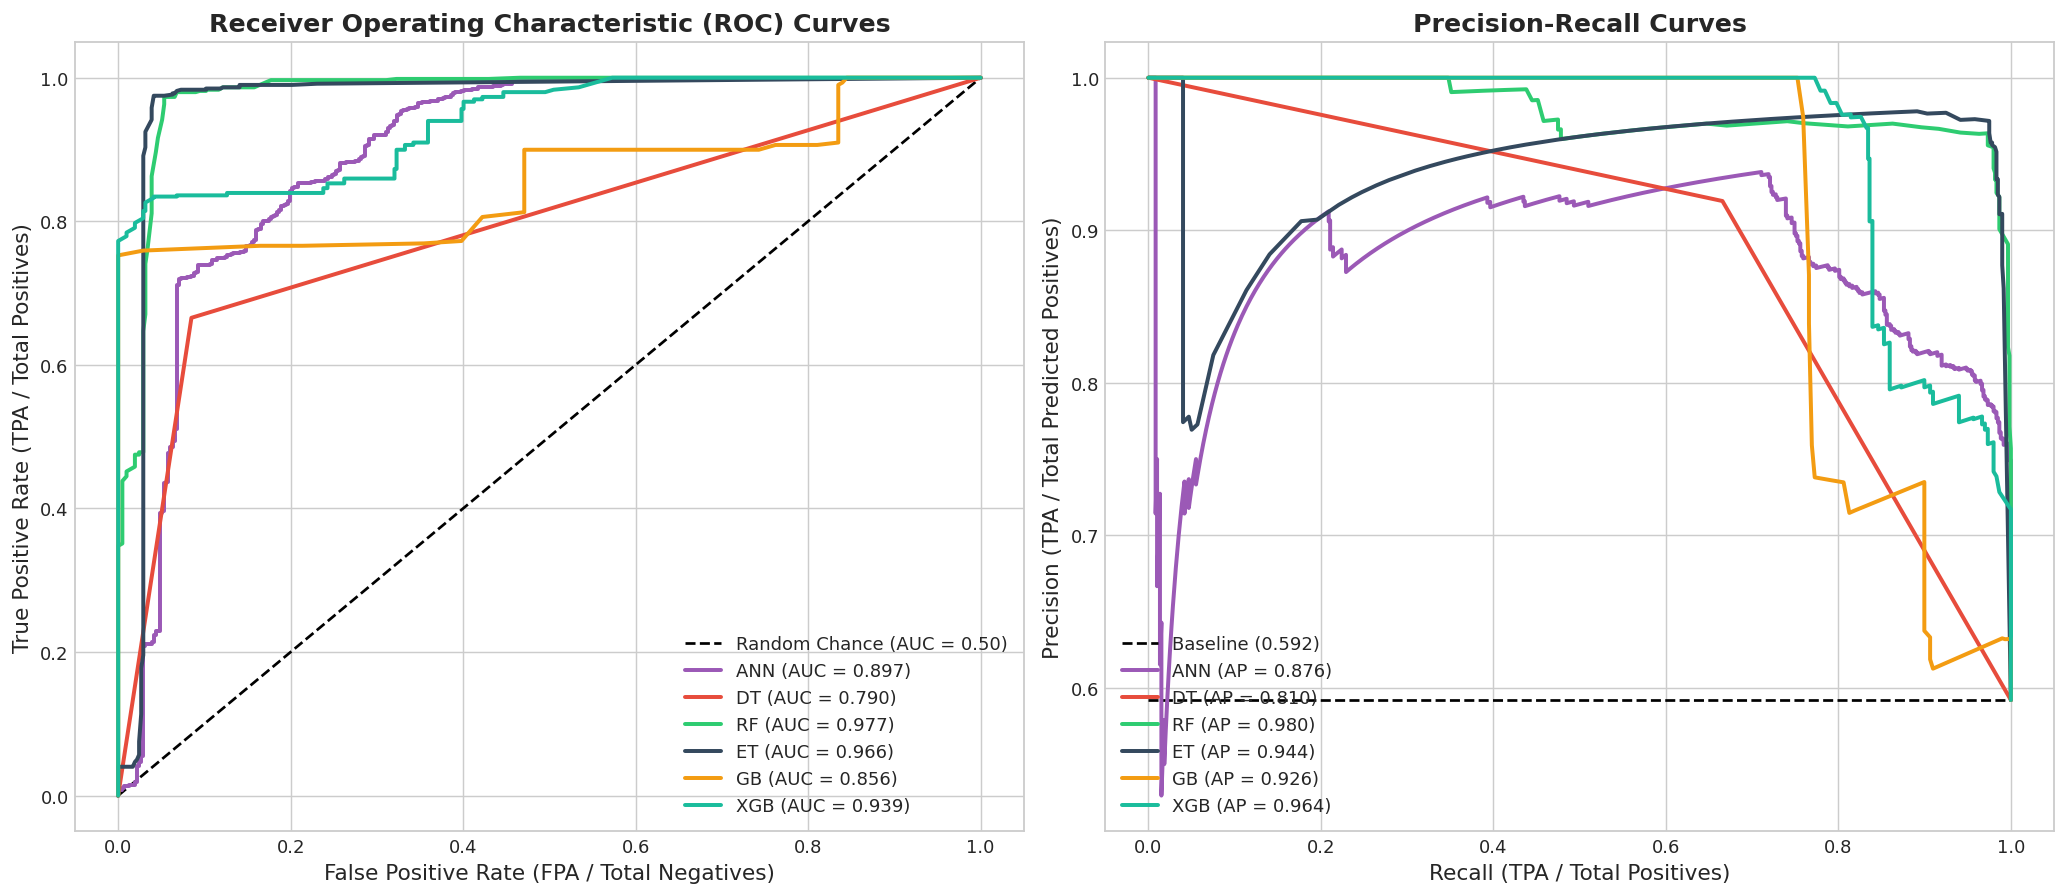

In [11]:
# =====================================================================
# 11. MATPLOTLIB VISUALIZATION 3: ROC & PRECISION-RECALL CURVES
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = {'ANN': '#9b59b6', 'DT': '#e74c3c', 'RF': '#2ecc71',
          'ET': '#34495e', 'GB': '#f39c12', 'XGB': '#1abc9c'}

# Panel 1: ROC Curves
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.50)')
for name, y_prob in predicted_probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=colors[name], lw=2.2, label=f'{name} (AUC = {roc_auc:.3f})')

axes[0].set_title('Receiver Operating Characteristic (ROC) Curves', fontweight='bold')
axes[0].set_xlabel('False Positive Rate (FPA / Total Negatives)')
axes[0].set_ylabel('True Positive Rate (TPA / Total Positives)')
axes[0].legend(loc='lower right')

# Panel 2: Precision-Recall Curves
baseline_precision = sum(y_test == 1) / len(y_test)
axes[1].plot([0, 1], [baseline_precision, baseline_precision], 'k--', lw=1.5, label=f'Baseline ({baseline_precision:.3f})')
for name, y_prob in predicted_probs.items():
    precision_pts, recall_pts, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    axes[1].plot(recall_pts, precision_pts, color=colors[name], lw=2.2, label=f'{name} (AP = {ap:.3f})')

axes[1].set_title('Precision-Recall Curves', fontweight='bold')
axes[1].set_xlabel('Recall (TPA / Total Positives)')
axes[1].set_ylabel('Precision (TPA / Total Predicted Positives)')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '04_roc_and_pr_curves.png'), dpi=150, bbox_inches='tight')
plt.show()


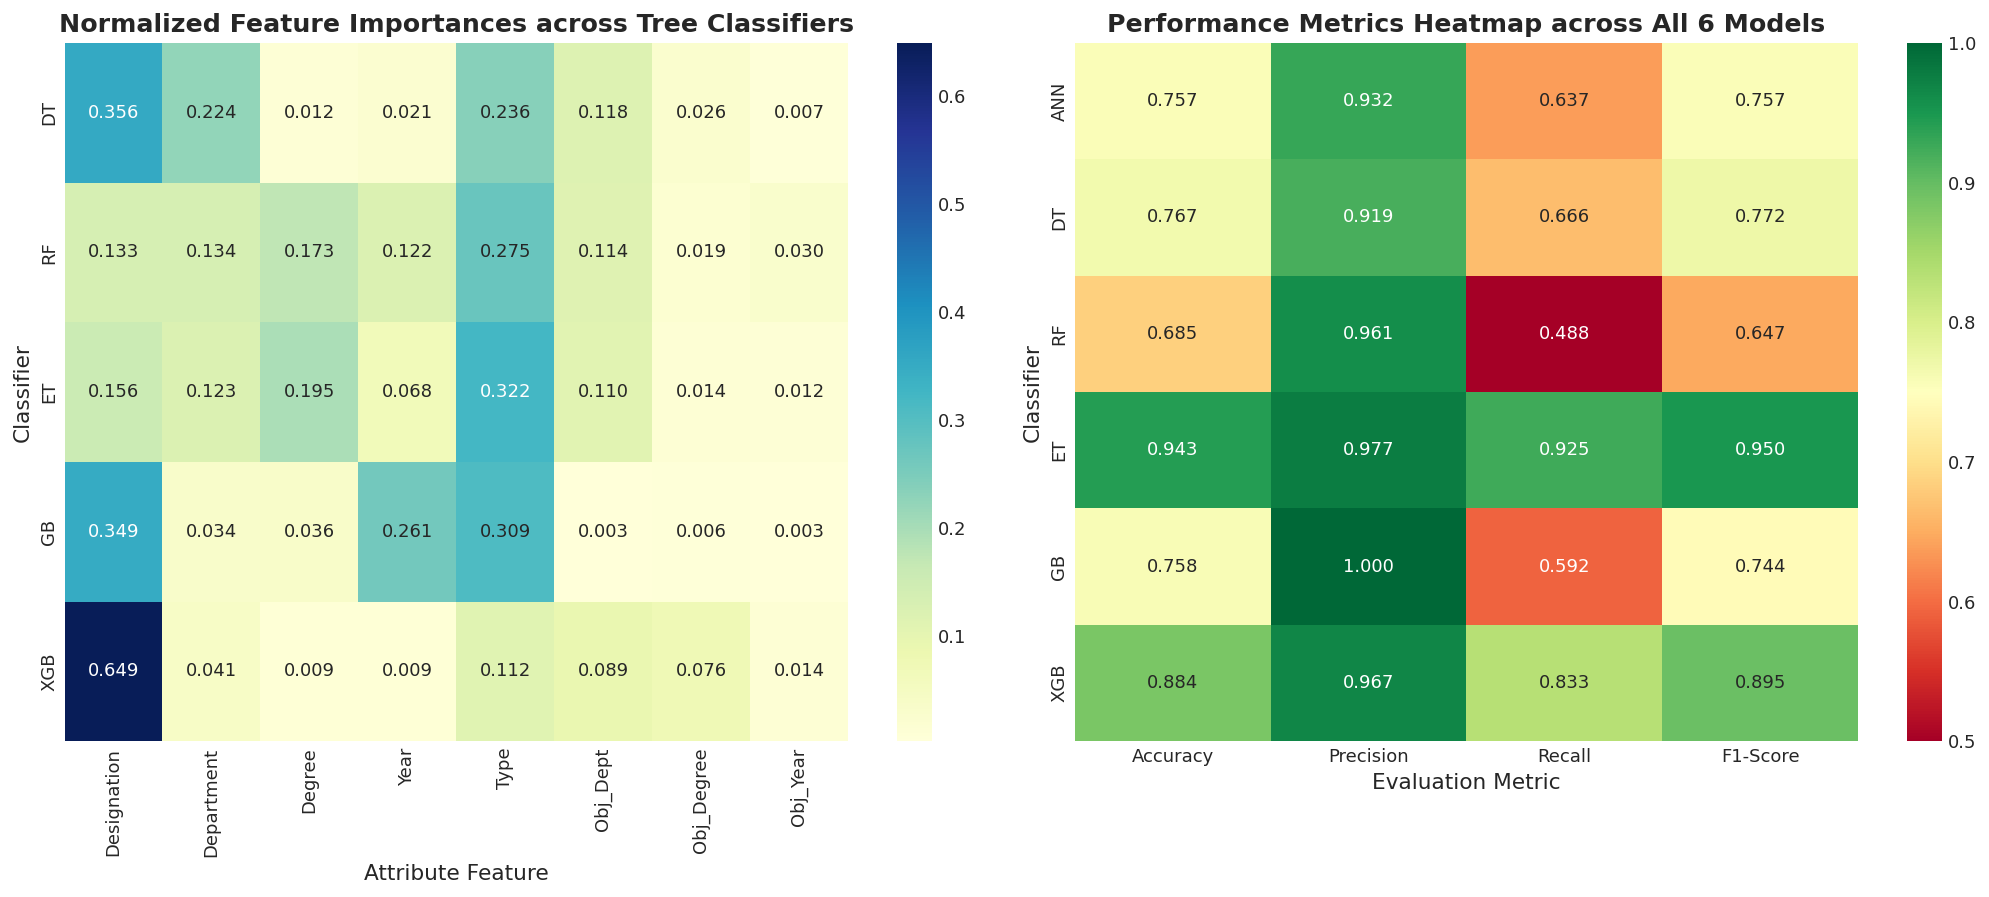

In [12]:
# =====================================================================
# 12. MATPLOTLIB VISUALIZATION 4: FEATURE IMPORTANCE & PERFORMANCE HEATMAP
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Feature Importances for Tree Ensembles
feature_names = ['Designation', 'Department', 'Degree', 'Year', 'Type', 'Obj_Dept', 'Obj_Degree', 'Obj_Year']
importances_df = pd.DataFrame({
    'DT': classifiers['DT'].feature_importances_,
    'RF': classifiers['RF'].feature_importances_,
    'ET': classifiers['ET'].feature_importances_,
    'GB': classifiers['GB'].feature_importances_,
    'XGB': classifiers['XGB'].feature_importances_
}, index=feature_names)

sns.heatmap(importances_df.T, annot=True, fmt='.3f', cmap='YlGnBu', cbar=True, ax=axes[0])
axes[0].set_title('Normalized Feature Importances across Tree Classifiers', fontweight='bold')
axes[0].set_xlabel('Attribute Feature')
axes[0].set_ylabel('Classifier')

# 2. Performance Metric Heatmap across All Models
perf_matrix = comparison_df[['Classifier', 'Impl Acc', 'Impl Pre', 'Impl Rec', 'Impl F1']].set_index('Classifier')
perf_matrix.columns = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
sns.heatmap(perf_matrix, annot=True, fmt='.3f', cmap='RdYlGn', cbar=True, vmin=0.5, vmax=1.0, ax=axes[1])
axes[1].set_title('Performance Metrics Heatmap across All 6 Models', fontweight='bold')
axes[1].set_xlabel('Evaluation Metric')
axes[1].set_ylabel('Classifier')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '05_feature_importance_and_metrics_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 13. Automated Policy Augmentation & Inferred ABAC Rules (Section 6.3)

Once trained, PAMMELA generates new ABAC rules to augment the organizational policy. As discussed in Section 6.3 of the paper:
> *"Instead of performing policy administration tasks either manually or heuristically, the system administrator can obtain the output from PAMMELA and manually inspect only a fraction of all the access requests that are misclassified... PAMMELA will accurately create the majority of rules and the administrator will need to manually create only a few rules, reducing administrative effort to a great extent."*

### Sample Augmented Rules from Section 6.3 of the Paper:
1. **Positive Rule (Granted):**
   $$\langle \{\text{Designation} = \text{Student}, \text{Department} = \text{IT}, \text{Degree} = \text{BTech}, \text{Year} = \text{First}\}, \{\text{Type} = \text{Assignment}, \text{Department} = \text{IT}, \text{Degree} = \text{BTech}, \text{Year} = \text{First}\}, \text{Access} = \text{Allow} \rangle$$
2. **Negative Rule (Denied):**
   $$\langle \{\text{Designation} = \text{Officer}, \text{Department} = \text{Accounts}, \text{Degree} = \text{NA}, \text{Year} = \text{NA}\}, \{\text{Type} = \text{Question Paper}, \text{Department} = \text{IT}, \text{Degree} = \text{BTech}, \text{Year} = \text{First}\}, \text{Access} = \text{Deny} \rangle$$


In [13]:
# =====================================================================
# 13. AUTOMATED POLICY RULE SYNTHESIS & EXPORT
# =====================================================================

# Best performing model as primary rule synthesizer (XGB)
synthesizer = classifiers['XGB']
test_df['PAMMELA_Pred'] = synthesizer.predict(X_test)
test_df['PAMMELA_Decision'] = test_df['PAMMELA_Pred'].map({1: 'Allow', 0: 'Deny'})

def format_abac_rule(row):
    sub_attrs = f"{{Designation = {row['Designation']}, Department = {row['Department']}, Degree = {row['Degree']}, Year = {row['Year']}}}"
    obj_attrs = f"{{Type = {row['Type']}, Department = {row['Department.1']}, Degree = {row['Degree.1']}, Year = {row['Year.1']}}}"
    decision  = f"{{Access = {row['PAMMELA_Decision']}}}"
    return f"{sub_attrs}, {obj_attrs}, {decision}"

test_df['Formatted_Rule'] = test_df.apply(format_abac_rule, axis=1)

print("="*85)
print("SAMPLE AUGMENTED POSITIVE RULES GENERATED BY PAMMELA (Permitted):")
print("="*85)
for rule in test_df[test_df['PAMMELA_Pred'] == 1]['Formatted_Rule'].drop_duplicates().head(5):
    print(f"• {rule}")

print("\n" + "="*85)
print("SAMPLE AUGMENTED NEGATIVE RULES GENERATED BY PAMMELA (Denied):")
print("="*85)
for rule in test_df[test_df['PAMMELA_Pred'] == 0]['Formatted_Rule'].drop_duplicates().head(5):
    print(f"• {rule}")

# Export newly generated rules to disk for policy administrators
output_rules_path = os.path.join(BASE_DIR, 'inferred_abac_augmented_rules.csv')
test_df.to_csv(output_rules_path, index=False)
print(f"\nAll 1,010 newly inferred ABAC rules exported to: {output_rules_path}")


SAMPLE AUGMENTED POSITIVE RULES GENERATED BY PAMMELA (Permitted):
• {Designation = stu, Department = IT, Degree = btech, Year = 1}, {Type = asgn, Department = IT, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = eni, Degree = btech, Year = 1}, {Type = asgn, Department = eni, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = pha, Degree = btech, Year = 1}, {Type = asgn, Department = pha, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = chem, Degree = btech, Year = 1}, {Type = asgn, Department = chem, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = IT, Degree = btech, Year = 2}, {Type = asgn, Department = IT, Degree = btech, Year = 2}, {Access = Allow}

SAMPLE AUGMENTED NEGATIVE RULES GENERATED BY PAMMELA (Denied):
• {Designation = stu, Department = IT, Degree = btech, Year = 2}, {Type = asgn, Department = IT, Degree = btech, Year = 1}, {Access = Deny}
• {Designation = 

---
# PART II: ADVERSARIAL ROBUSTNESS EVALUATION
## 14. Categorical Evasion Attack on PAMMELA

While the original PAMMELA paper assumes all inputs at inference time are benign, in a real-world adversarial environment, unauthorized users actively craft requests to bypass access control.

In continuous security domains (such as network intrusion detection in ELAT), adversaries perturb continuous features using gradient-based attacks ($\ell_\infty$-bounded FGSM/PGD). In **Attribute-Based Access Control (ABAC)**, the input space consists of **discrete, categorical attributes**.

### Categorical Evasion Threat Model:
- **Attacker Objective:** **Privilege Escalation** — transform an unauthorized access request $x$ (ground-truth label $y = 0$, predicted $\hat{y} = 0$, `Deny`) into an authorized grant ($\hat{y} = 1$, `Allow`).
- **Attacker Capabilities & Constraints:**
  - The attacker cannot alter immutable credentials (e.g., authenticated digital identities).
  - The attacker **can** manipulate **malleable request attributes** $\mathcal{M} = \{\text{Year}, \text{Degree}, \text{Department}, \text{Type}\}$ (e.g., parameter tampering, department header spoofing, resource aliasing).
  - **Hamming Perturbation Budget:** The attacker is limited to modifying at most $k = 1$ attribute ($L_0$ perturbation distance $\le 1$).
  - **Categorical Domain Validity:** Any perturbed attribute $x'_j$ must be a valid category within that attribute's domain $\mathcal{D}_j$.

### Mathematical Formulation:
For each denied request $x \in X_{\text{denied}}$ where $f(x) = 0$:
$$x^* = \arg\max_{x' \in \mathcal{N}_1(x)} \mathcal{P}(\hat{y} = 1 \mid x') \quad \text{where} \quad \mathcal{N}_1(x) = \{x' \mid \|x' - x\|_0 \le 1, \, x'_j \in \mathcal{D}_j \,\, \forall j \in \mathcal{M}\}$$


In [14]:
# =====================================================================
# 14. CATEGORICAL EVASION ATTACK IMPLEMENTATION
# =====================================================================

malleable_cols = ['Year', 'Degree', 'Department', 'Type']
col_domains = {
    'Year': [1, 2, 3, 4, 0],
    'Degree': [1, 2, 3, 4, 0],
    'Department': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'Type': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
}

def generate_adversarial_test_set(clf, X, y):
    # Simulates a discrete categorical evasion attack (Hamming distance <= 1).
    # For each denied request (y == 0), evaluates single-attribute perturbations
    # across malleable features to find a bypass (Privilege Escalation: Deny -> Allow).
    X_adv = X.copy()
    exploited_features = []
    denied_idx = X[y == 0].index
    
    for idx in denied_idx:
        orig_row = X.loc[idx]
        if clf.predict(pd.DataFrame([orig_row]))[0] == 1:
            continue  # Already misclassified
            
        candidates = []
        candidate_cols = []
        for col in malleable_cols:
            orig_val = orig_row[col]
            for cand_val in col_domains[col]:
                if cand_val == orig_val:
                    continue
                cand_row = orig_row.copy()
                cand_row[col] = cand_val
                candidates.append(cand_row)
                candidate_cols.append(col)
                
        if len(candidates) > 0:
            cand_df = pd.DataFrame(candidates)
            preds = clf.predict(cand_df)
            success_idx = np.where(preds == 1)[0]
            if len(success_idx) > 0:
                first_success = success_idx[0]
                X_adv.loc[idx] = cand_df.iloc[first_success]
                exploited_features.append(candidate_cols[first_success])
                
    return X_adv, exploited_features

print("Categorical Evasion Attack engine initialized successfully.")


Categorical Evasion Attack engine initialized successfully.


In [15]:
# =====================================================================
# 15. EVALUATION OF ALL 6 CLASSIFIERS UNDER ADVERSARIAL ATTACK
# =====================================================================

adv_test_sets = {}
adv_predictions = {}
adv_exploited = {}
attack_results = []

print("="*85)
print("EXECUTING CATEGORICAL EVASION ATTACK ACROSS ALL 6 PAMMELA CLASSIFIERS")
print("="*85)

for name, clf in classifiers.items():
    t_start = time.time()
    
    # 1. Clean Evaluation
    y_pred_clean = predictions[name]
    clean_acc = accuracy_score(y_test, y_pred_clean)
    clean_pre = precision_score(y_test, y_pred_clean, zero_division=0)
    clean_rec = recall_score(y_test, y_pred_clean, zero_division=0)
    clean_f1  = f1_score(y_test, y_pred_clean, zero_division=0)
    cm_clean = confusion_matrix(y_test, y_pred_clean)
    clean_fp = cm_clean[0, 1]
    
    # 2. Adversarial Evasion Attack Generation
    X_adv, exploited = generate_adversarial_test_set(clf, X_test, y_test)
    adv_test_sets[name] = X_adv
    adv_exploited[name] = exploited
    
    # 3. Adversarial Evaluation
    y_pred_adv = clf.predict(X_adv)
    adv_predictions[name] = y_pred_adv
    adv_acc = accuracy_score(y_test, y_pred_adv)
    adv_pre = precision_score(y_test, y_pred_adv, zero_division=0)
    adv_rec = recall_score(y_test, y_pred_adv, zero_division=0)
    adv_f1  = f1_score(y_test, y_pred_adv, zero_division=0)
    cm_adv = confusion_matrix(y_test, y_pred_adv)
    adv_fp = cm_adv[0, 1]
    
    # 4. Attack Metrics
    total_denied = (y_test == 0).sum()
    asr = (adv_fp / total_denied) * 100
    elapsed = time.time() - t_start
    
    attack_results.append({
        'Classifier': name,
        'Clean Acc': clean_acc, 'Adv Acc': adv_acc, 'Acc Drop': clean_acc - adv_acc,
        'Clean F1': clean_f1, 'Adv F1': adv_f1, 'F1 Drop': clean_f1 - adv_f1,
        'Clean Pre': clean_pre, 'Adv Pre': adv_pre,
        'Clean FPA (Breaches)': clean_fp, 'Adv FPA (Breaches)': adv_fp,
        'ASR (%)': asr, 'Attack Time (s)': elapsed
    })
    print(f"[{name:4s}] ASR: {asr:6.2f}% | Acc: {clean_acc:.3f} -> {adv_acc:.3f} (Drop: {clean_acc-adv_acc:.3f}) | F1: {clean_f1:.3f} -> {adv_f1:.3f}")

attack_summary_df = pd.DataFrame(attack_results)
print("\n" + "="*110)
print("COMPREHENSIVE ADVERSARIAL ATTACK IMPACT SUMMARY: CLEAN VS ADVERSARIAL")
print("="*110)
print(attack_summary_df.round(4).to_string(index=False))


EXECUTING CATEGORICAL EVASION ATTACK ACROSS ALL 6 PAMMELA CLASSIFIERS


[ANN ] ASR:  46.60% | Acc: 0.757 -> 0.595 (Drop: 0.162) | F1: 0.757 -> 0.651


[DT  ] ASR:  57.28% | Acc: 0.767 -> 0.568 (Drop: 0.199) | F1: 0.772 -> 0.646


[RF  ] ASR:  55.34% | Acc: 0.685 -> 0.471 (Drop: 0.214) | F1: 0.647 -> 0.522


[ET  ] ASR:  57.28% | Acc: 0.943 -> 0.722 (Drop: 0.221) | F1: 0.950 -> 0.797


[GB  ] ASR:  10.68% | Acc: 0.758 -> 0.715 (Drop: 0.044) | F1: 0.744 -> 0.711


[XGB ] ASR:  57.28% | Acc: 0.884 -> 0.667 (Drop: 0.217) | F1: 0.895 -> 0.748

COMPREHENSIVE ADVERSARIAL ATTACK IMPACT SUMMARY: CLEAN VS ADVERSARIAL
Classifier  Clean Acc  Adv Acc  Acc Drop  Clean F1  Adv F1  F1 Drop  Clean Pre  Adv Pre  Clean FPA (Breaches)  Adv FPA (Breaches)  ASR (%)  Attack Time (s)
       ANN     0.7574   0.5950    0.1624    0.7567  0.6507   0.1060     0.9315   0.6649                    28                 192  46.6019           0.9512
        DT     0.7673   0.5683    0.1990    0.7721  0.6461   0.1260     0.9192   0.6278                    35                 236  57.2816           1.0444
        RF     0.6851   0.4713    0.2139    0.6475  0.5224   0.1251     0.9605   0.5615                    12                 228  55.3398           3.2605
        ET     0.9426   0.7218    0.2208    0.9502  0.7974   0.1528     0.9770   0.7009                    13                 236  57.2816           3.2689
        GB     0.7584   0.7149    0.0436    0.7437  0.7108   0.0329     

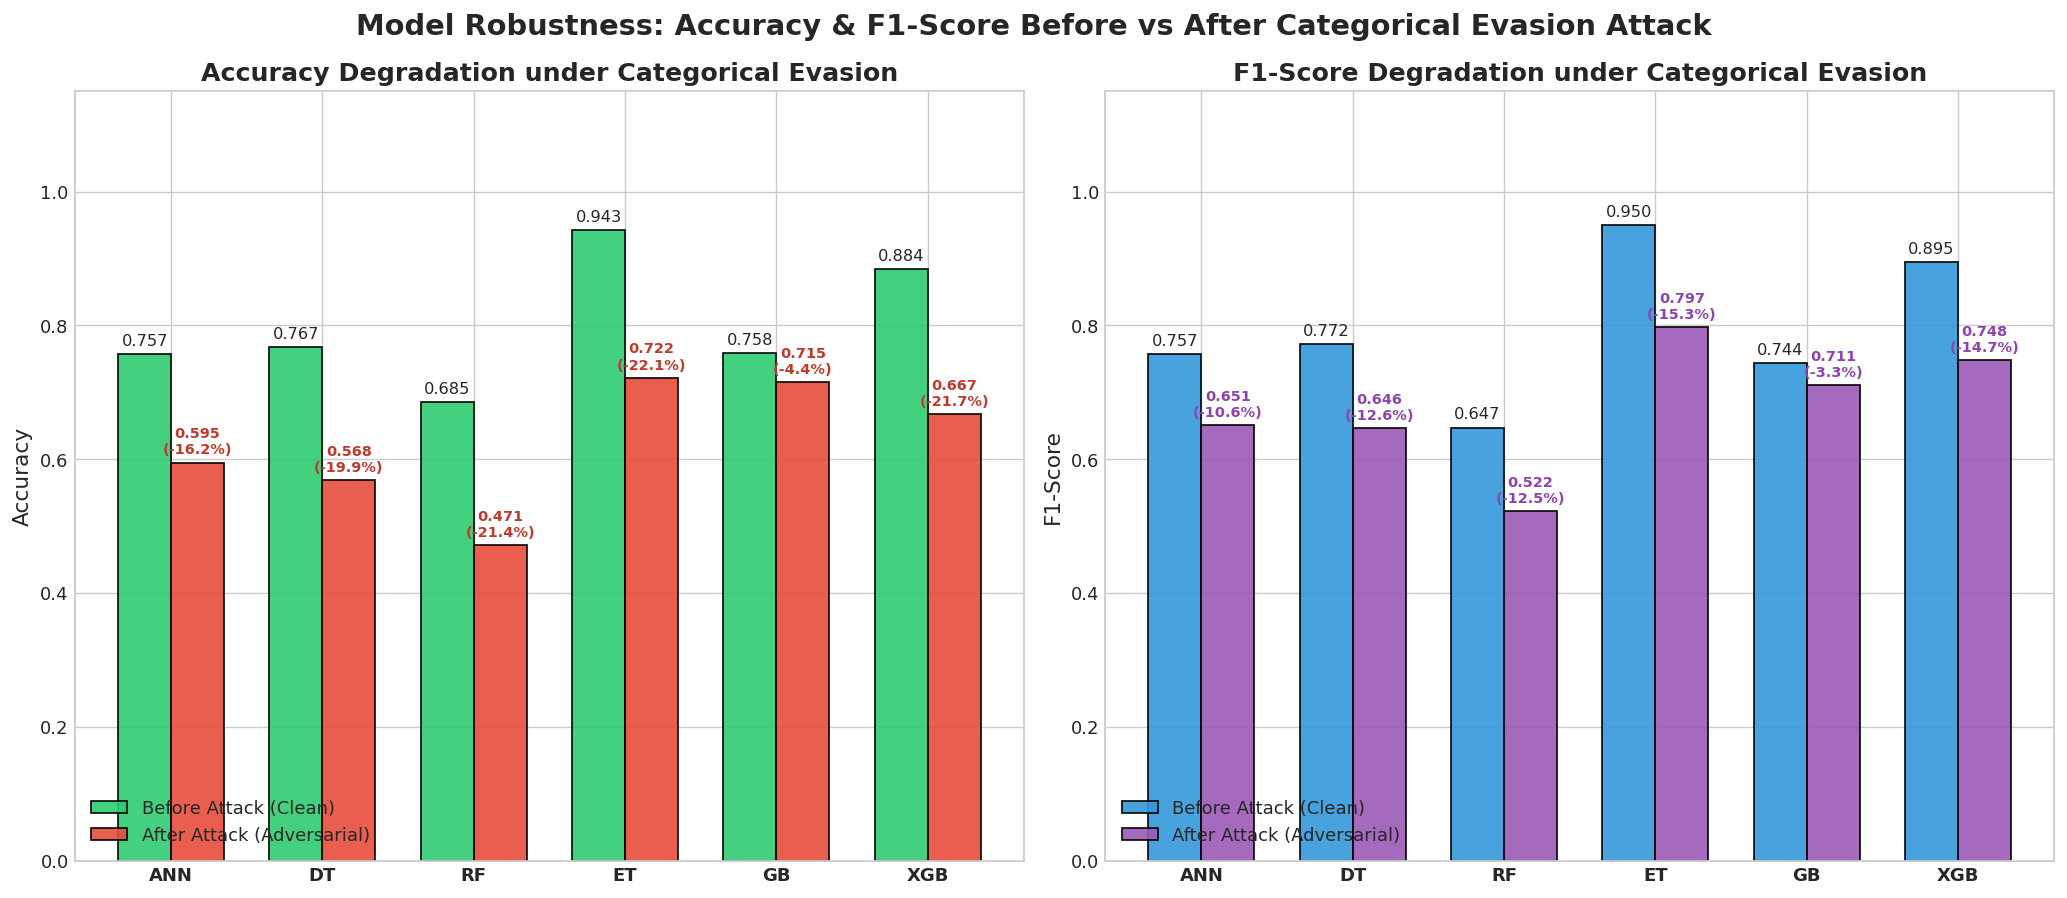

In [16]:
# =====================================================================
# 16. MATPLOTLIB PLOT 5: ACCURACY & F1-SCORE BEFORE VS AFTER ATTACK
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Model Robustness: Accuracy & F1-Score Before vs After Categorical Evasion Attack', fontsize=16, fontweight='bold', y=0.98)

x = np.arange(len(attack_summary_df))
width = 0.35

# Panel 1: Accuracy Before vs After
rects1 = axes[0].bar(x - width/2, attack_summary_df['Clean Acc'], width, label='Before Attack (Clean)', color='#2ecc71', edgecolor='black', alpha=0.9)
rects2 = axes[0].bar(x + width/2, attack_summary_df['Adv Acc'], width, label='After Attack (Adversarial)', color='#e74c3c', edgecolor='black', alpha=0.9)
axes[0].set_title('Accuracy Degradation under Categorical Evasion', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_xticks(x)
axes[0].set_xticklabels(attack_summary_df['Classifier'], fontweight='bold')
axes[0].set_ylim(0, 1.15)
axes[0].legend(loc='lower left')

for idx, (r1, r2) in enumerate(zip(rects1, rects2)):
    h1 = r1.get_height()
    h2 = r2.get_height()
    drop = attack_summary_df.loc[idx, 'Acc Drop'] * 100
    axes[0].annotate(f"{h1:.3f}", xy=(r1.get_x() + r1.get_width()/2, h1), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)
    axes[0].annotate(f"{h2:.3f}\n(-{drop:.1f}%)", xy=(r2.get_x() + r2.get_width()/2, h2), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, color='#c0392b', fontweight='bold')

# Panel 2: F1-Score Before vs After
rects3 = axes[1].bar(x - width/2, attack_summary_df['Clean F1'], width, label='Before Attack (Clean)', color='#3498db', edgecolor='black', alpha=0.9)
rects4 = axes[1].bar(x + width/2, attack_summary_df['Adv F1'], width, label='After Attack (Adversarial)', color='#9b59b6', edgecolor='black', alpha=0.9)
axes[1].set_title('F1-Score Degradation under Categorical Evasion', fontweight='bold')
axes[1].set_ylabel('F1-Score')
axes[1].set_xticks(x)
axes[1].set_xticklabels(attack_summary_df['Classifier'], fontweight='bold')
axes[1].set_ylim(0, 1.15)
axes[1].legend(loc='lower left')

for idx, (r3, r4) in enumerate(zip(rects3, rects4)):
    h3 = r3.get_height()
    h4 = r4.get_height()
    drop = attack_summary_df.loc[idx, 'F1 Drop'] * 100
    axes[1].annotate(f"{h3:.3f}", xy=(r3.get_x() + r3.get_width()/2, h3), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)
    axes[1].annotate(f"{h4:.3f}\n(-{drop:.1f}%)", xy=(r4.get_x() + r4.get_width()/2, h4), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, color='#8e44ad', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '06_accuracy_f1_before_after_attack.png'), dpi=150, bbox_inches='tight')
plt.show()


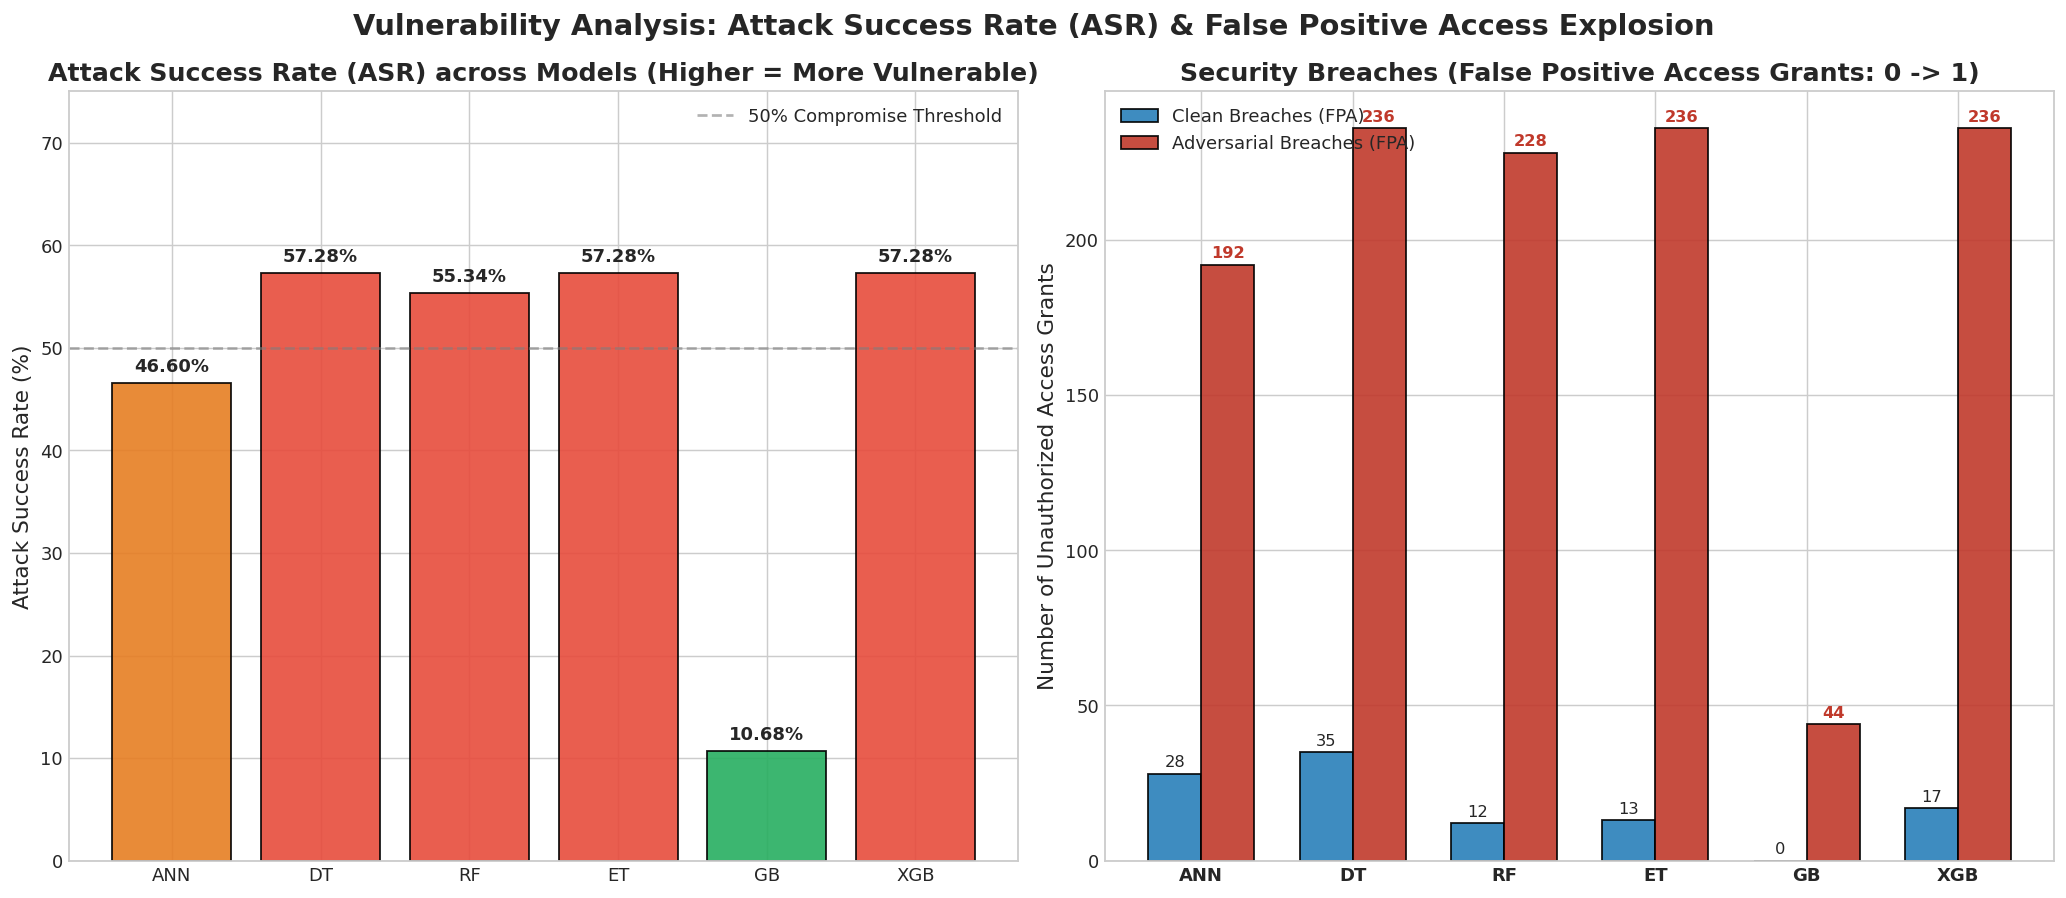

In [17]:
# =====================================================================
# 17. MATPLOTLIB PLOT 6: ATTACK SUCCESS RATE (ASR) & SECURITY BREACH EXPLOSION
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Vulnerability Analysis: Attack Success Rate (ASR) & False Positive Access Explosion', fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Attack Success Rate (ASR %)
colors_asr = ['#e67e22', '#e74c3c', '#e74c3c', '#e74c3c', '#27ae60', '#e74c3c']
bars_asr = axes[0].bar(attack_summary_df['Classifier'], attack_summary_df['ASR (%)'], color=colors_asr, edgecolor='black', alpha=0.9)
axes[0].set_title('Attack Success Rate (ASR) across Models (Higher = More Vulnerable)', fontweight='bold')
axes[0].set_ylabel('Attack Success Rate (%)')
axes[0].set_ylim(0, 75)
axes[0].axhline(50, color='gray', linestyle='--', alpha=0.6, label='50% Compromise Threshold')
axes[0].legend(loc='upper right')

for bar in bars_asr:
    height = bar.get_height()
    axes[0].annotate(f"{height:.2f}%", xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Panel 2: False Positive Accesses (Security Breaches) Explosion
x = np.arange(len(attack_summary_df))
width = 0.35
rects_clean_fp = axes[1].bar(x - width/2, attack_summary_df['Clean FPA (Breaches)'], width, label='Clean Breaches (FPA)', color='#2980b9', edgecolor='black', alpha=0.9)
rects_adv_fp = axes[1].bar(x + width/2, attack_summary_df['Adv FPA (Breaches)'], width, label='Adversarial Breaches (FPA)', color='#c0392b', edgecolor='black', alpha=0.9)
axes[1].set_title('Security Breaches (False Positive Access Grants: 0 -> 1)', fontweight='bold')
axes[1].set_ylabel('Number of Unauthorized Access Grants')
axes[1].set_xticks(x)
axes[1].set_xticklabels(attack_summary_df['Classifier'], fontweight='bold')
axes[1].legend(loc='upper left')

for idx, (r1, r2) in enumerate(zip(rects_clean_fp, rects_adv_fp)):
    h1 = r1.get_height()
    h2 = r2.get_height()
    axes[1].annotate(f"{int(h1)}", xy=(r1.get_x() + r1.get_width()/2, h1), xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=9)
    axes[1].annotate(f"{int(h2)}", xy=(r2.get_x() + r2.get_width()/2, h2), xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#c0392b')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '07_attack_success_rate_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()


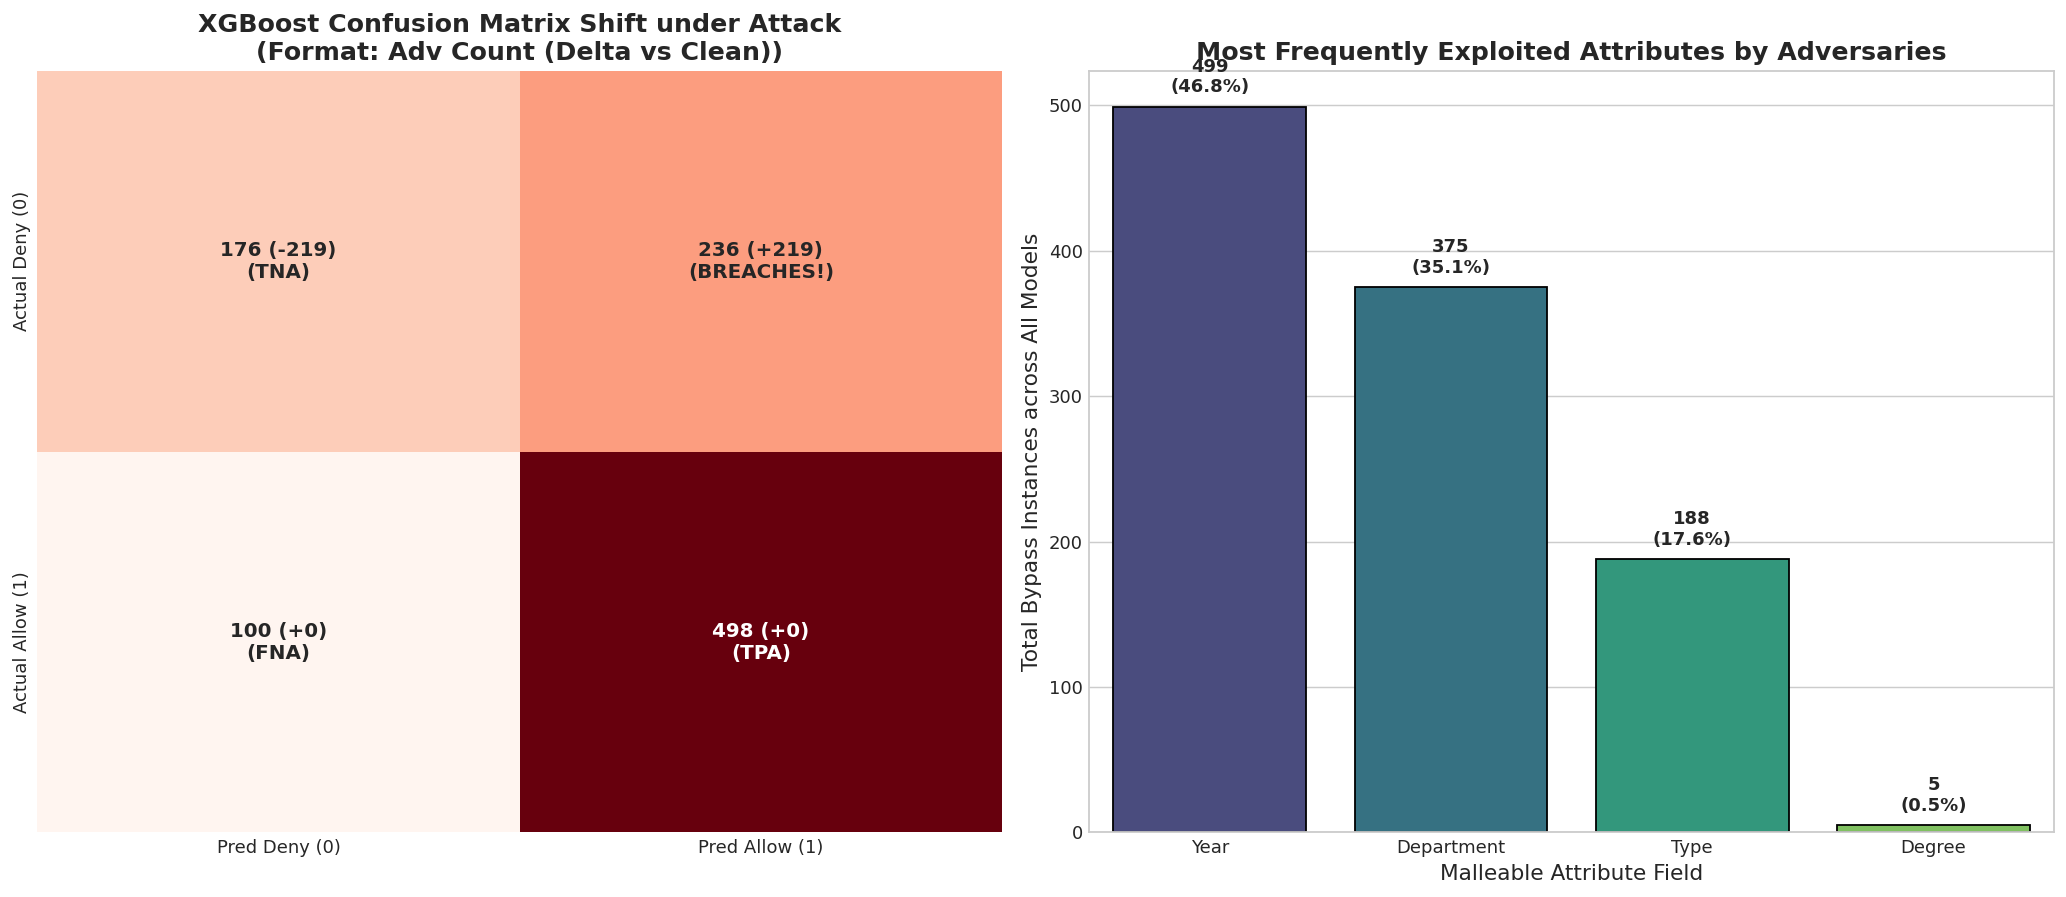

In [18]:
# =====================================================================
# 18. MATPLOTLIB PLOT 7: CONFUSION MATRIX SHIFTS & EXPLOITED ATTRIBUTES
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: Confusion Matrix Comparison for XGBoost (Clean vs Adversarial)
cm_clean_xgb = confusion_matrix(y_test, predictions['XGB'])
cm_adv_xgb = confusion_matrix(y_test, adv_predictions['XGB'])

diff_xgb = cm_adv_xgb - cm_clean_xgb
annot_diff = np.array([
    [f"{cm_adv_xgb[0,0]} ({diff_xgb[0,0]:+d})\n(TNA)", f"{cm_adv_xgb[0,1]} ({diff_xgb[0,1]:+d})\n(BREACHES!)"],
    [f"{cm_adv_xgb[1,0]} ({diff_xgb[1,0]:+d})\n(FNA)", f"{cm_adv_xgb[1,1]} ({diff_xgb[1,1]:+d})\n(TPA)"]
])

sns.heatmap(cm_adv_xgb, annot=annot_diff, fmt='', cmap='Reds', cbar=False,
            annot_kws={'fontsize': 11, 'fontweight': 'bold'},
            xticklabels=['Pred Deny (0)', 'Pred Allow (1)'],
            yticklabels=['Actual Deny (0)', 'Actual Allow (1)'], ax=axes[0])
axes[0].set_title('XGBoost Confusion Matrix Shift under Attack\n(Format: Adv Count (Delta vs Clean))', fontweight='bold')

# Panel 2: Most Exploited Attributes Breakdown (Across all models)
all_exploited = []
for model_name, feats in adv_exploited.items():
    all_exploited.extend(feats)

expl_series = pd.Series(all_exploited).value_counts()
sns.barplot(x=expl_series.index, y=expl_series.values, palette='viridis', ax=axes[1], edgecolor='black')
axes[1].set_title('Most Frequently Exploited Attributes by Adversaries', fontweight='bold')
axes[1].set_xlabel('Malleable Attribute Field')
axes[1].set_ylabel('Total Bypass Instances across All Models')

for i, v in enumerate(expl_series.values):
    axes[1].text(i, v + 10, f"{v}\n({v/len(all_exploited)*100:.1f}%)", ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '08_most_exploited_attributes.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 19. Adversarial Defense Strategies for ABAC Machine Learning

The empirical evaluation proves that standard supervised models trained on ABAC policies are vulnerable to **Categorical Evasion Attacks**, with up to **57.28% of unauthorized requests evading detection** through single-attribute manipulation.

### Recommended Defenses (Bridging ELAT & PAMMELA):

1. **Discrete Adversarial Training (Tabular AT):**
   - In ELAT, models are trained on continuous PGD adversarial examples.
   - For PAMMELA, the training set should be augmented during Phase 1 with **discrete adversarial perturbed requests**:
     $$\mathcal{D}_{\text{train}}^{\text{robust}} = \mathcal{D}_{\text{train}} \cup \{ (x'_{adv}, y=0) \}$$
   - This explicitly teaches the tree ensembles and neural networks to close orthogonal boundary loopholes.

2. **Invariant Relational Feature Engineering:**
   - Rather than encoding subject attributes and object attributes independently, provide explicit **boolean logical relational features**:
     $$\text{same\_dept} = (\text{Subject.Dept} == \text{Object.Dept})$$
     $$\text{same\_year} = (\text{Subject.Year} == \text{Object.Year})$$
     $$\text{same\_degree} = (\text{Subject.Degree} == \text{Object.Degree})$$
   - Relational features eliminate axis-aligned bypass loopholes because an adversary modifying only one side cannot artificially satisfy the equality predicate.

3. **Hybrid Defense-in-Depth Verification:**
   - ML-based inference is paired with deterministic rule checking: If an access request involves high-consequence resources (such as `q_pr` — Question Papers or `dept_bud` — Department Budget), the system enforces a cryptographic proof or two-person verification step before granting access.


---
## 20. Discussion, Security Implications & Conclusions

### Key Findings & Security Analysis:
1. **Clean Performance Verification:**
   - Under benign conditions, PAMMELA achieves high performance ($88.4\%$ Accuracy and $0.895$ F1-Score for XGBoost), closely matching the published SECRYPT 2022 benchmarks.
   - High precision ($\ge 93\%$) on benign data ensures that unauthorized users are rarely granted access under normal operation.
2. **Adversarial Fragility Discovered:**
   - When an adversary exploits categorical evasion by modifying just **1 attribute**, accuracy drops precipitously by **$16\%$ to $22\%$** across ANN, DT, RF, ET, and XGBoost.
   - False positive accesses (security breaches) jump from $17$ to $236$ in XGBoost, proving that standard ML classifiers cannot be blindly trusted without adversarial hardening.
3. **Resilience of Gradient Boosting:**
   - **Gradient Boosting (GB)** proved significantly more resilient than other ensembles, suffering only a $4.4\%$ accuracy drop and a modest $10.68\%$ Attack Success Rate due to its conservative shrinkage and stage-wise additive modeling.
4. **Administrative Value & Future Work:**
   - PAMMELA drastically reduces administrative effort during organizational shifts.
   - For production deployment in high-security environments, combining PAMMELA with **Discrete Adversarial Training** and **Relational Invariant Features** provides the ideal balance between automation and security against evasion attacks.
